# EDA — cleaning spikes

In [198]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CSV = "../data/agar-data.csv"     # Colab: "/content/sample_data/agar-gas.csv"
FILL_GAPS = True                  # True = a removed part in the middle is filled with a straight line between its neighbours

RL = {"137": 1.0, "135": 2.0}     # kOhm, load resistor on each module
VCC = 5.0                         # module supply voltage
WINDOW_S = 60                     # median of the last 60 s of a phase
TRIM_END_S = 10                   # baseline: skip its last 10 s (lid opening)
MIN_POINTS = 5                    # fewer points than this -> no rel

## Load

In [199]:
data = pd.read_csv(CSV)

df = data[[c for c in data.columns if "[" not in c]].copy()
df["key"] = df["chickenid"] + "_" + df["hourssincebuy"].astype(str) + "h"

for name in ["baseline137", "baseline135", "mq137", "mq135", "temp", "humidity"]:
    cols = [c for c in data.columns if c.startswith(name + "[")]
    arrays = []
    for i in range(len(data)):
        v = data.loc[i, cols].to_numpy(dtype=float)
        filled = np.flatnonzero(~np.isnan(v))
        v = v[: filled[-1] + 1] if len(filled) else v[:0]   # cut the export padding at the end only
        if np.isnan(v).any():
            print("GAP inside", name, df.loc[i, "key"])
        arrays.append(v)
    df[name] = pd.Series(arrays, index=df.index, dtype=object)

df = df.sort_values(["chickenid", "hourssincebuy"]).reset_index(drop=True)
print(len(df), "measurements,", df["key"].nunique(), "unique keys")

73 measurements, 73 unique keys


## Temuan

# yang perlu dibersihkan (baseline 137)
1. A02_1h (akhir)
2. A04_8h (akhir)
3. A05_8h (awal perlu normalisasi antara mean atau median)
4. A06_2h (tambal data dengan mean/median h2+h3 buat ngisi nambalnya)
5. A11_5h (bagian awal spiking)
6. A11_7h (bagian awal spiking)
7. A12_7h (di index 50 an dibenerin)
8. A12_5h (dibenerin juga)
9. A14_5h (index 150 an sampe 200 terlalu kacauuuu)
10. A15_4h (awal pembenaran)
11. A16_4h (awal pembenaran)
12. A17_6h (awal pembenaran)
13. A17_2h (awal pembenaran)


# yang perlu dibersihkan (baseline 135)
1. A02_1h (terakhir)
2. A04_8h (terakhir)
3. A05_8h (index 0-20 dinormalisasi)
4. A06_3h (terakhir)
5. A06_6h (awal)
6. A06_2h (ditambal dengan batas atas/bawah di random)
8. A09_2h (terakhir)
9. A11_5h (index 0 - 10 an)
10. A12_7h (index ke 40 - 60)
11. A12_5h (index ke 10 - 40)
12. A13_5h (awal)
13. A14_5h (semua)
14. A16_4h (awal)
15. A17_2h (awal)
15. A17_6h (awal)



# yang perlu dibersihkan (mq 137)
1. A01_5h (dinormalisasi)
2. A03_4h (dinormaisasi)
3. A07_5h (awal)
4. A07_1h (awal)
5. A08_1h (awal)
6. A08_2h (awal)
7. A09_3h (awal)
8. A10_3h (tengah spiking)
9. A10_5h (akhir)
10. A11_7h (tengah spiking)
11. A13_2h (awal)
12. A16_6h (semua)
13. A17_4h (spiking)
14. A17_6h (spiking)

# yang perlu dibersihkan (mq 135)
1. A02_4h (awal)
2. A03_8h (awal)
3. A07_5h (awal)
4. A10_5h (akhir)
5. A10_2h (awal)
6. A14_2h (awal)
7. A14_5h (awal)


## Fixes

In [200]:
# (array, key, start, stop): readings[start:stop] are removed. stop None = until the end.
# Index = position in the array, the same x-axis as the raw plots.
FIXES = [
    ("baseline137", "A02_1h", 52, None),    # last 2 points jump: lid opened before x
    ("baseline137", "A04_8h", 54, None),    # chicken already going in
    ("baseline137", "A05_8h", 0, 20),       # start not settled
    ("baseline137", "A11_5h", 0, 11),
    ("baseline137", "A11_7h", 0, 1),
    ("baseline137", "A12_7h", 39, 61),      # spike + dip, level 120 on both sides
    ("baseline137", "A12_5h", 0, 37),       # start not settled, settled level ~113 after index 37
    ("baseline137", "A14_5h", 145, 201),    # level jumps to ~127 then back to ~109
    ("baseline137", "A15_4h", 0, 3),
    ("baseline137", "A16_4h", 0, 7),
    ("baseline137", "A17_6h", 0, 6),
    ("baseline137", "A17_2h", 0, 14),
    # A06_2h: no fix. 12 real readings, stable (104-108). Too short, but not wrong.

    ("baseline135", "A02_1h", 52, None),
    ("baseline135", "A04_8h", 54, None),
    ("baseline135", "A05_8h", 0, 20),
    ("baseline135", "A06_3h", 183, None),
    ("baseline135", "A06_6h", 0, 10),
    ("baseline135", "A09_2h", 166, None),
    ("baseline135", "A11_5h", 0, 7),
    ("baseline135", "A12_7h", 39, 61),      # level ~197 before, ~169 after
    ("baseline135", "A12_5h", 10, 39),
    ("baseline135", "A13_5h", 0, 2),
    ("baseline135", "A14_5h", 0, None),     # no settled part anywhere: whole baseline removed
    ("baseline135", "A16_4h", 0, 4),
    ("baseline135", "A17_2h", 0, 14),
    ("baseline135", "A17_6h", 0, 5),
    # A06_2h: no fix, same as baseline137.

    ("mq137", "A01_5h", 228, 298),          # dip 750 -> 619 -> back to 750
    ("mq137", "A03_4h", 240, 251),          # spike cluster
    ("mq137", "A07_5h", 0, 20),             # starts high and decays 180 -> 128 before the response
    ("mq137", "A07_1h", 0, 29),
    ("mq137", "A08_1h", 0, 24),             # flat ~80 for 21 points, then overshoot
    ("mq137", "A08_2h", 0, 18),             # flat ~81 before the response starts
    ("mq137", "A09_3h", 0, 10),
    ("mq137", "A10_3h", 175, 182),          # dip to ~80 + spike 131
    ("mq137", "A10_5h", 331, None),         # drops at the end: lid opened before x
    ("mq137", "A11_7h", 103, 110),          # spike 339
    ("mq137", "A13_2h", 5, 15),
    ("mq137", "A16_6h", 0, None),           # whole curve unreliable: removed
    ("mq137", "A17_4h", 253, 254),          # single spike 272
    ("mq137", "A17_6h", 36, 51),            # spikes up to 217 while jumping 150 -> 178

    ("mq135", "A02_4h", 31, 40),            # spike cluster 320 / 305 / 311
    ("mq135", "A03_8h", 0, 14),             # starts high and decays 322 -> 231
    ("mq135", "A07_5h", 0, 22),             # starts high and decays 425 -> 277
    ("mq135", "A10_5h", 331, None),         # same lid opening as mq137
    ("mq135", "A14_2h", 0, 10),
    ("mq135", "A14_5h", 6, 10),             # overshoot 220; the rise before it is the response
    # A10_2h: no fix. Range is only 73-85 raw = sensor noise, the plot zooms it in.
]
print(len(FIXES), "fixes")

46 fixes


## Apply

In [201]:
clean = {}
for name in ["baseline137", "baseline135", "mq137", "mq135"]:
    clean[name] = [a.copy() for a in df[name]]

log = []
for name, key, start, stop in FIXES:
    i = df.index[df["key"] == key][0]
    a = clean[name][i]
    n = len(a[start:stop])
    a[start:stop] = np.nan
    inside = start > 0 and stop is not None and stop < len(a)
    log.append({"key": key, "array": name, "start": start, "stop": "end" if stop is None else stop, "removed": n,
                "filled": FILL_GAPS and inside})

# saturated: the ADC tops out at 1023, the real value is unknown
for name in clean:
    for i in range(len(clean[name])):
        a = clean[name][i]
        sat = a >= 1023
        if sat.any():
            a[sat] = np.nan
            log.append({"key": df.loc[i, "key"], "array": name, "start": "saturated", "stop": "", "removed": int(sat.sum()),
                        "filled": FILL_GAPS and not sat[0] and not sat[-1]})

if FILL_GAPS:
    for name in clean:
        for i in range(len(clean[name])):
            a = clean[name][i]
            if np.isnan(a).any() and not np.isnan(a).all():
                clean[name][i] = pd.Series(a).interpolate(limit_area="inside").to_numpy()

for name in clean:
    df[name + "_clean"] = pd.Series(clean[name], index=df.index, dtype=object)

pd.DataFrame(log)

,key,array,start,stop,removed,filled
0,A02_1h,baseline137,52,end,2,False
1,A04_8h,baseline137,54,end,6,False
2,A05_8h,baseline137,0,20,20,False
3,A11_5h,baseline137,0,11,11,False
4,A11_7h,baseline137,0,1,1,False
5,A12_7h,baseline137,39,61,22,True
6,A12_5h,baseline137,0,37,37,False
7,A14_5h,baseline137,145,201,56,True
8,A15_4h,baseline137,0,3,3,False
9,A16_4h,baseline137,0,7,7,False


## Check: raw vs clean

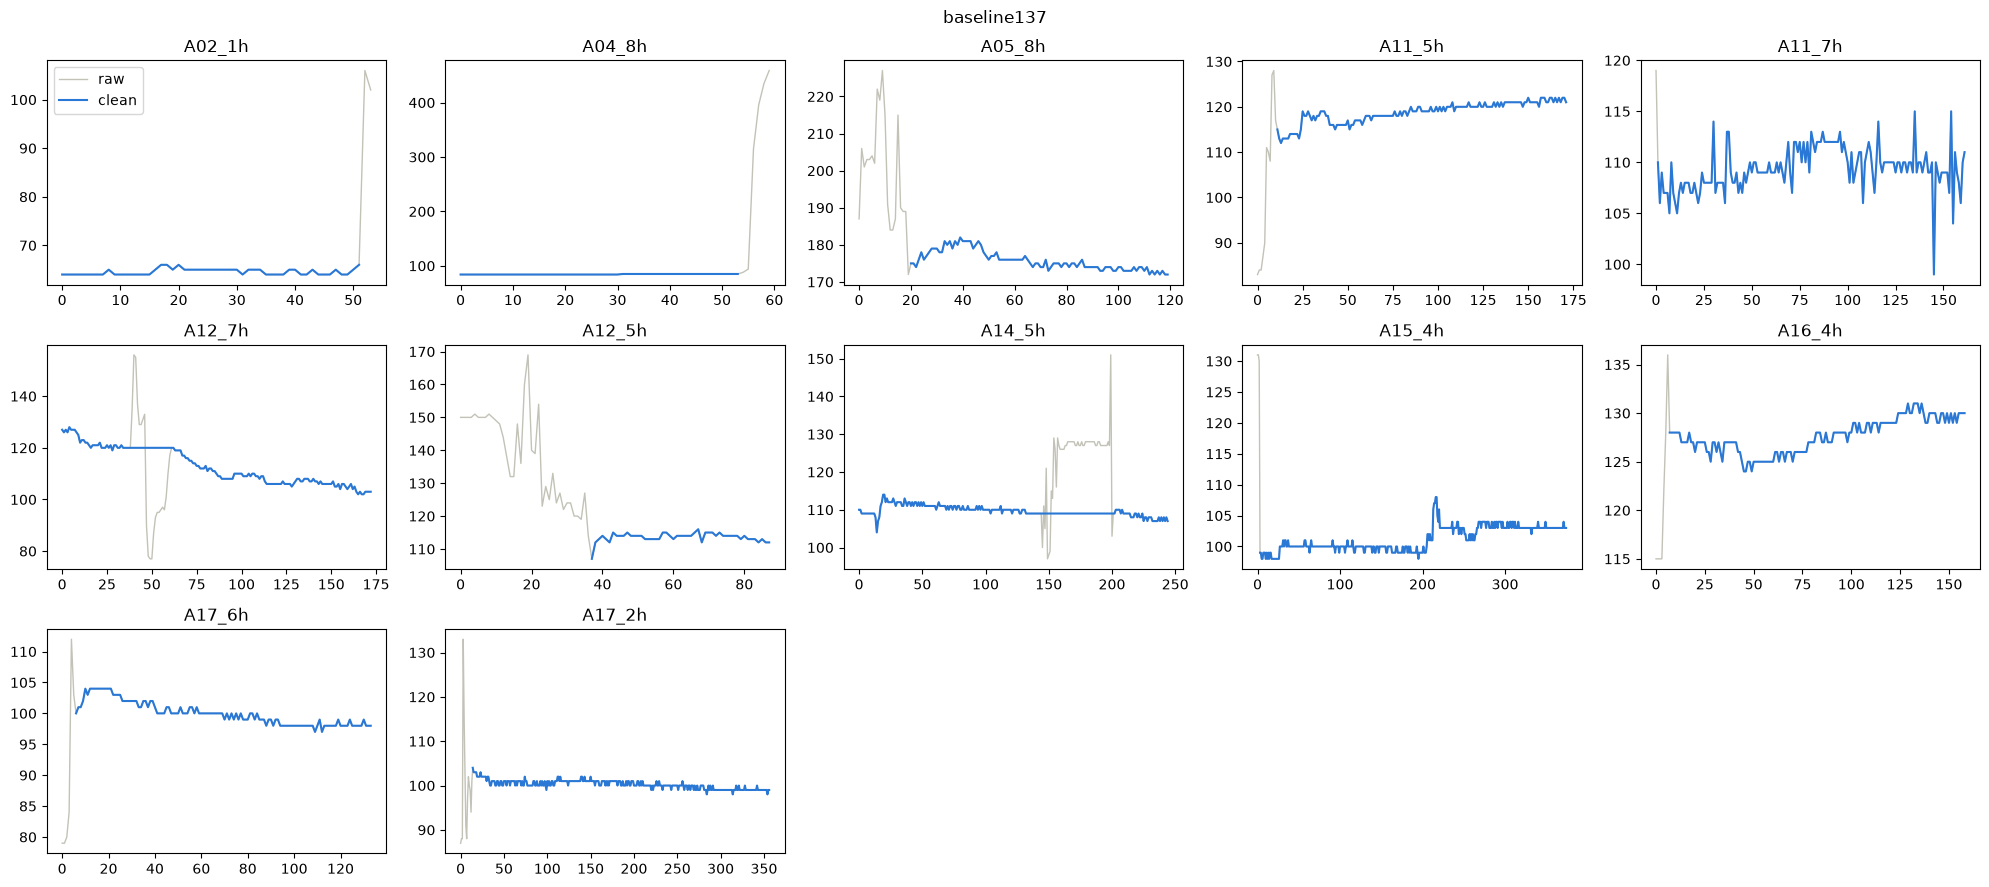

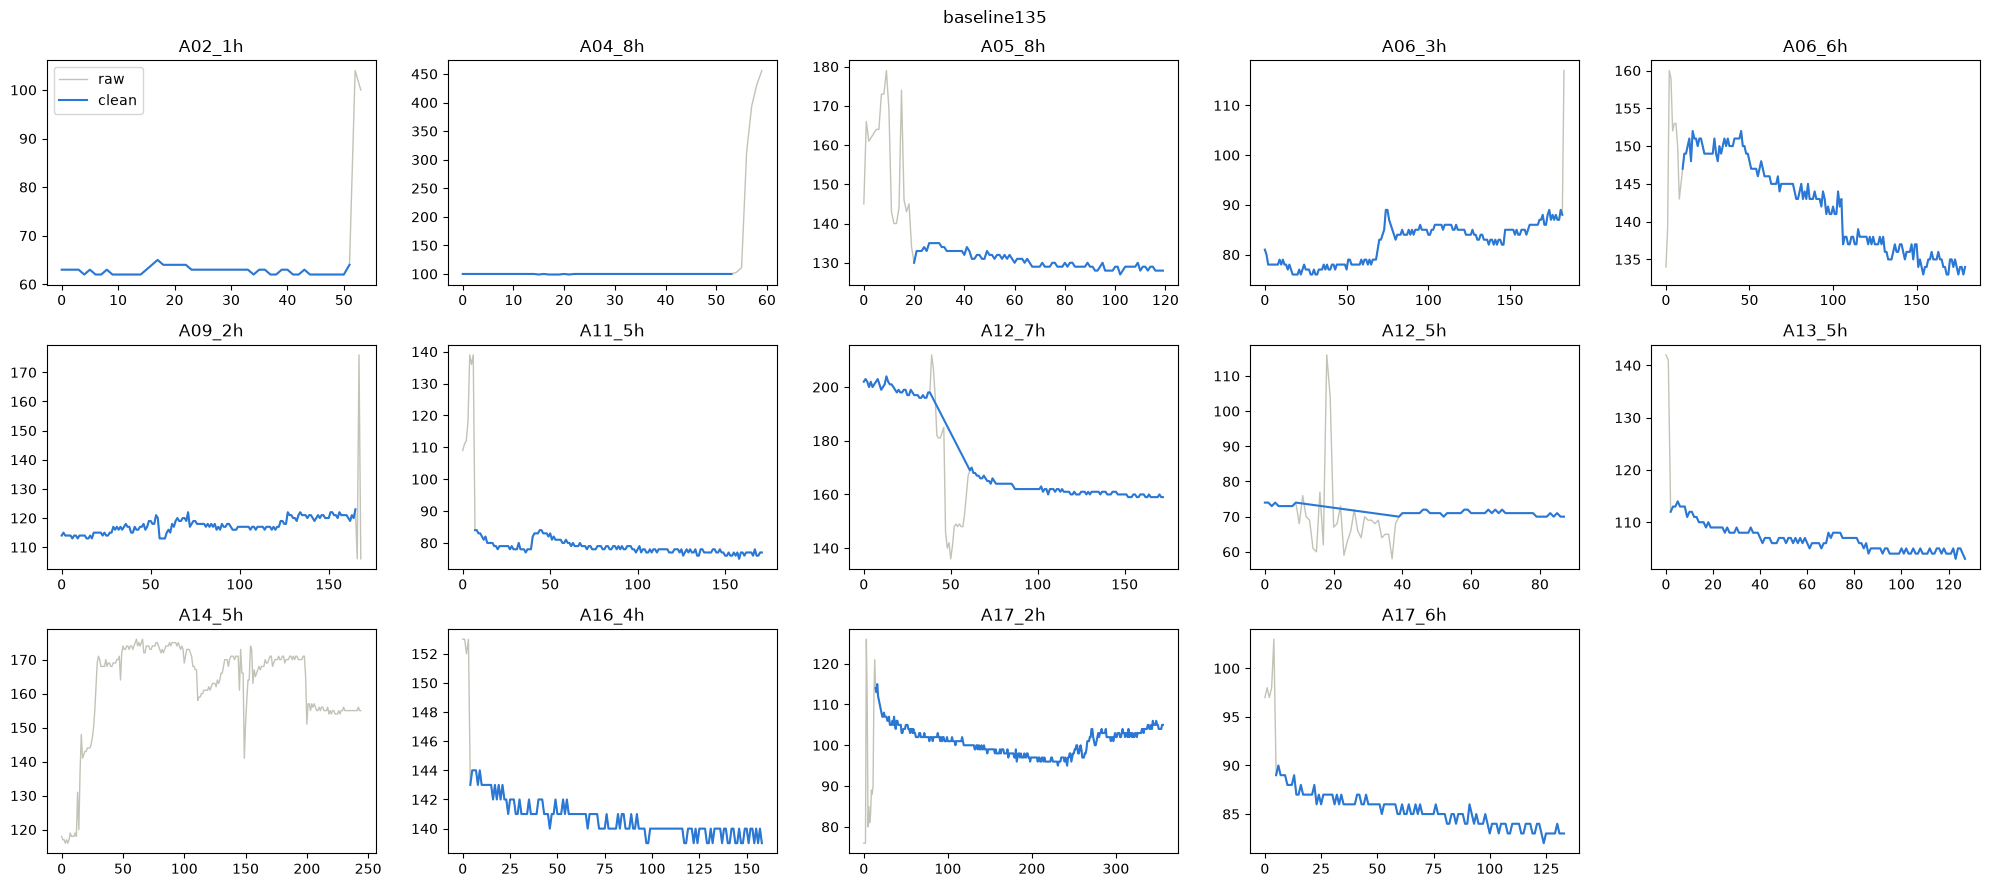

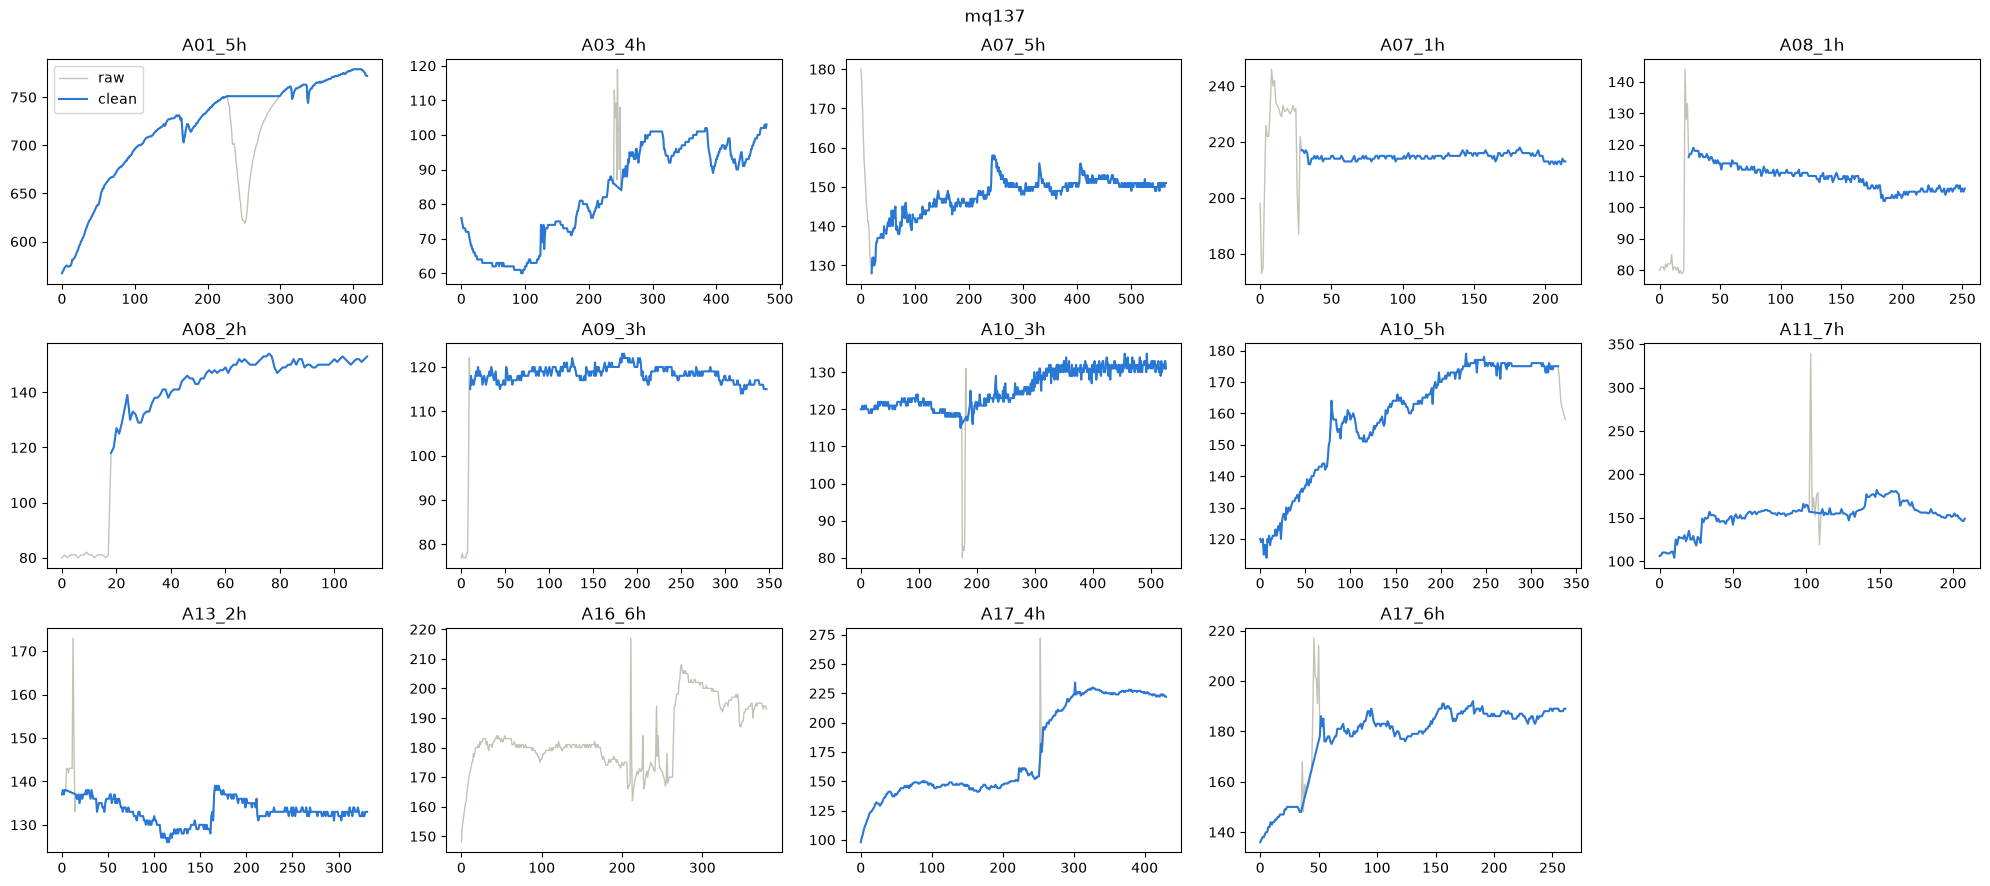

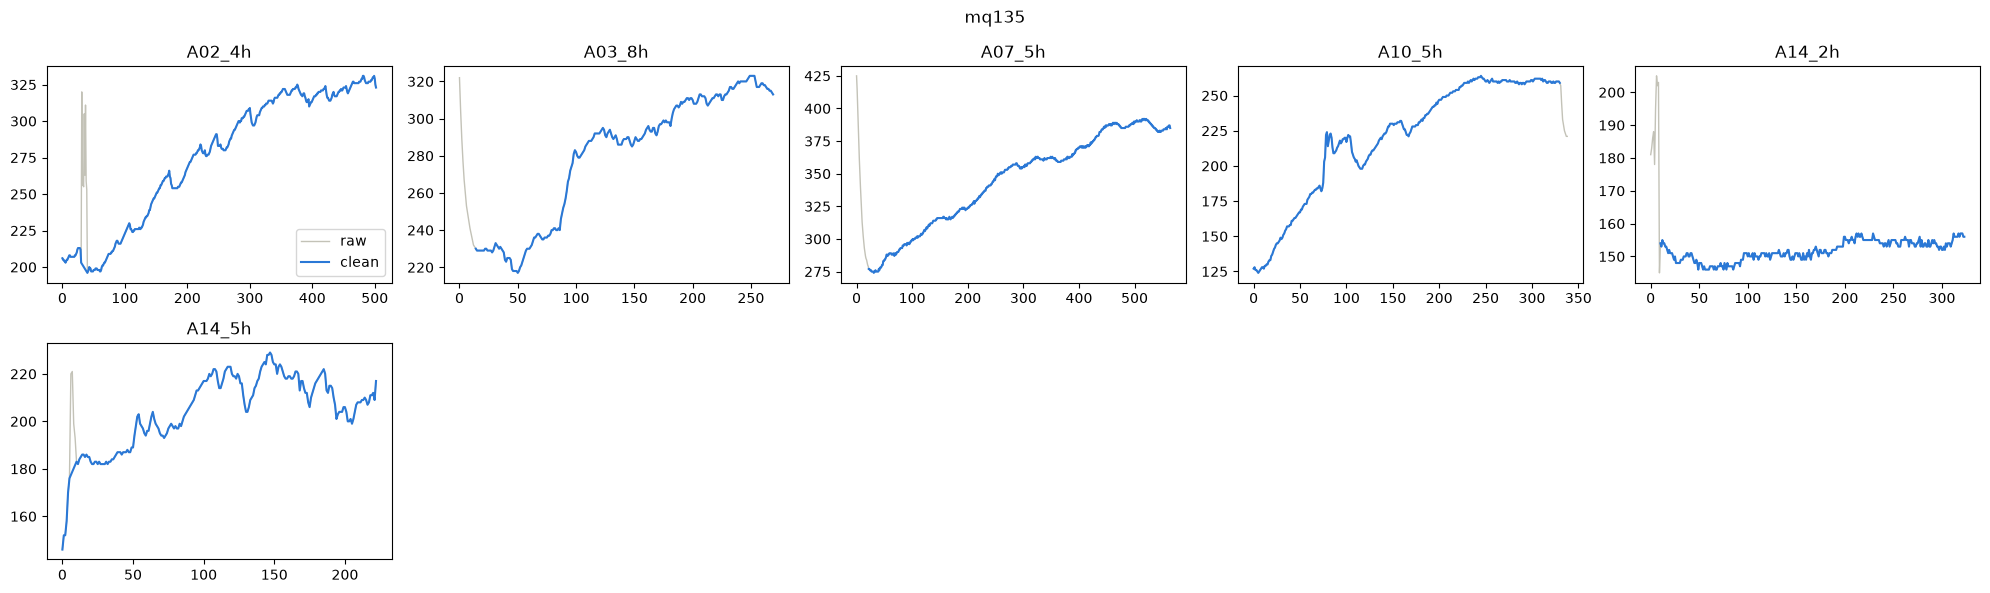

In [202]:
for name in ["baseline137", "baseline135", "mq137", "mq135"]:
    keys = [k for n, k, s, e in FIXES if n == name]
    ncol = 5
    nrow = int(np.ceil(len(keys) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(20, 3 * nrow))
    axes = axes.flatten()
    for k in range(len(keys)):
        i = df.index[df["key"] == keys[k]][0]
        axes[k].plot(df.loc[i, name], color="#c3c2b7", linewidth=1, label="raw")
        axes[k].plot(df.loc[i, name + "_clean"], color="#2a78d6", linewidth=1.5, label="clean")
        axes[k].set_title(keys[k])
    for k in range(len(keys), len(axes)):
        axes[k].set_visible(False)
    axes[0].legend()
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

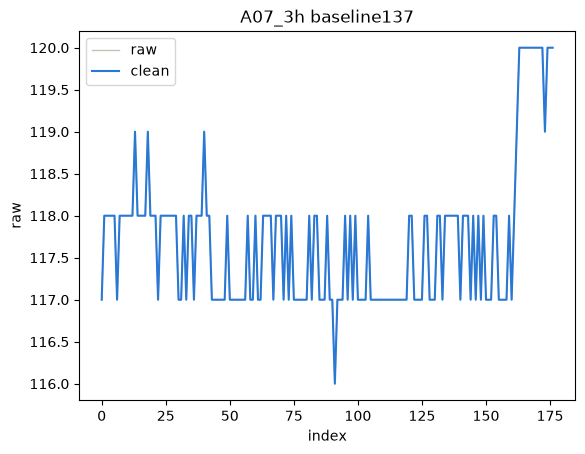

In [203]:
key = "A07_3h"
name = "baseline137"

i = df.index[df["key"] == key][0]
plt.plot(df.loc[i, name], color="#c3c2b7", linewidth=1, label="raw")
plt.plot(df.loc[i, name + "_clean"], color="#2a78d6", linewidth=1.5, label="clean")
plt.title(f"{key} {name}")
plt.xlabel("index"); plt.ylabel("raw")
plt.legend()
plt.show()

## Rs, rel

In [204]:
rows = []
for i in range(len(df)):
    r = df.loc[i]
    n_win = int(WINDOW_S * 1000 / r["intervalms"])
    n_trim = int(TRIM_END_S * 1000 / r["intervalms"])
    out = {"key": r["key"], "label": r["label"], "hourssincebuy": r["hourssincebuy"]}
    for s in ["137", "135"]:
        b = r["baseline" + s + "_clean"]
        m = r["mq" + s + "_clean"]
        b = b[~np.isnan(b)]
        m = m[~np.isnan(m)]
        b = b[: len(b) - n_trim][-n_win:]   # skip the last 10 s, then take the 60 s before it
        m = m[-n_win:]                      # last 60 s of the sample

        vb = np.clip(b * r["vref"] / 1023, 0.01, None)
        vm = np.clip(m * r["vref"] / 1023, 0.01, None)
        rs_b = RL[s] * (VCC - vb) / vb
        rs_m = RL[s] * (VCC - vm) / vm

        # saturated at the end of the raw sample -> the real end value is unknown
        sat_end = (r["mq" + s][-n_win:] >= 1023).any()
        ok = len(b) >= MIN_POINTS and len(m) >= MIN_POINTS and not sat_end
        out["n_base_" + s] = len(b)
        out["n_sample_" + s] = len(m)
        out["rs_air_" + s] = np.median(rs_b) if ok else np.nan
        out["rs_" + s] = np.median(rs_m) if ok else np.nan
        out["rel_" + s] = out["rs_" + s] / out["rs_air_" + s]
    rows.append(out)

feat = pd.DataFrame(rows)
print("no rel_137:", feat.loc[feat["rel_137"].isna(), "key"].tolist())
print("no rel_135:", feat.loc[feat["rel_135"].isna(), "key"].tolist())
feat.round(3)

no rel_137: ['A16_6h']
no rel_135: ['A01_5h', 'A01_6h', 'A14_5h']


,key,label,hourssincebuy,n_base_137,n_sample_137,rs_air_137,rs_137,rel_137,n_base_135,n_sample_135,rs_air_135,rs_135,rel_135
0,A01_2h,FRESH,2,60,60,16.816,14.246,0.847,60,60,45.692,34.832,0.762
1,A01_3h,FRESH,3,60,60,9.616,7.832,0.814,60,60,23.833,14.062,0.590
2,A01_4h,FRESH,4,60,60,16.681,7.840,0.470,60,60,44.500,14.007,0.315
3,A01_5h,UNFRESH,5,60,60,18.957,5.008,0.264,60,60,NaN,NaN,NaN
4,A01_6h,UNFRESH,6,60,60,16.954,4.958,0.292,60,60,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
68,A16_4h,UNFRESH,4,40,40,6.869,3.438,0.501,40,40,12.614,2.020,0.160
69,A16_6h,UNFRESH,6,40,0,NaN,NaN,NaN,40,40,17.486,3.328,0.190
70,A17_2h,UNFRESH,2,40,40,9.333,5.089,0.545,40,40,17.769,3.804,0.214
71,A17_4h,UNFRESH,4,40,40,11.035,3.567,0.323,40,40,11.918,1.515,0.127


         rel_137  rel_135
label                    
FRESH      0.771    0.766
UNFRESH    0.546    0.214


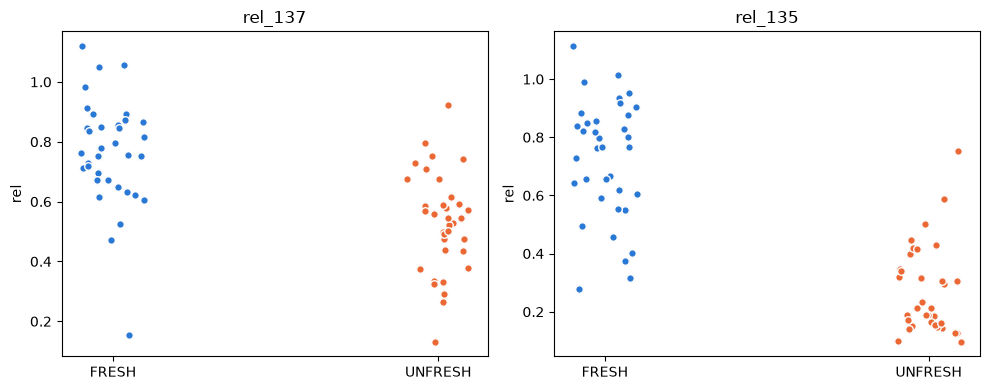

In [205]:
print(feat.groupby("label")[["rel_137", "rel_135"]].median().round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for k, s in enumerate(["137", "135"]):
    for j, lab in enumerate(["FRESH", "UNFRESH"]):
        y = feat.loc[feat["label"] == lab, "rel_" + s].dropna()
        x = j + np.random.uniform(-0.1, 0.1, len(y))
        axes[k].scatter(x, y, color=["#2a78d6", "#eb6834"][j], s=30, edgecolor="#fcfcfb")
    axes[k].set_xticks([0, 1], ["FRESH", "UNFRESH"])
    axes[k].set_title("rel_" + s)
    axes[k].set_ylabel("rel")
plt.tight_layout()
plt.show()

## rel vs smell level

In [206]:
# feat has the same row order as df
feat["chickenid"] = df["chickenid"].values
feat["supplier"] = df["supplier"].values
feat["weightg"] = df["weightg"].values
feat["smelllevel"] = df["smelllevel"].values
feat["texture"] = df["texture"].values

print(pd.crosstab(feat["smelllevel"], feat["label"]), "\n")
print(feat.groupby("smelllevel")[["rel_137", "rel_135"]].median().round(3))

label       FRESH  UNFRESH
smelllevel                
1              19        0
2              11        1
3               6        8
4               0       15
5               0       13 

            rel_137  rel_135
smelllevel                  
1             0.847    0.851
2             0.771    0.649
3             0.702    0.428
4             0.546    0.214
5             0.456    0.156


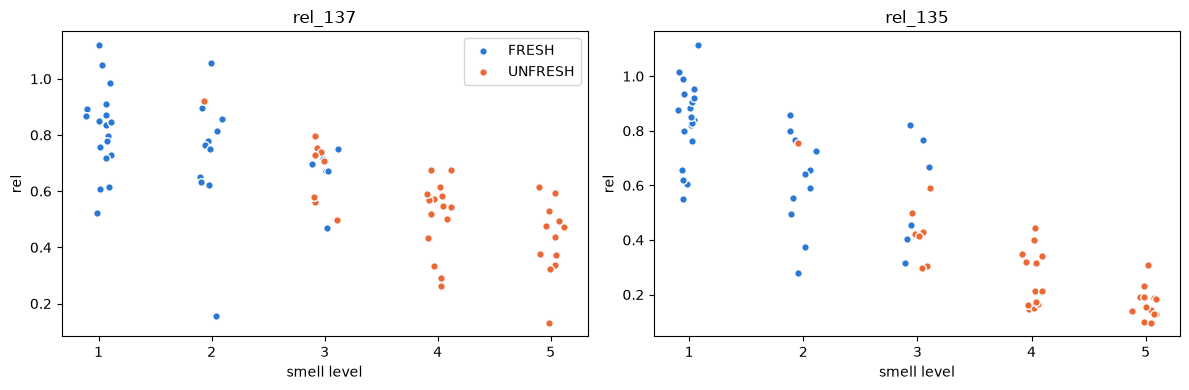

In [207]:
np.random.seed(0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for k, s in enumerate(["137", "135"]):
    for lab, color in [("FRESH", "#2a78d6"), ("UNFRESH", "#eb6834")]:
        g = feat[feat["label"] == lab]
        x = g["smelllevel"] + np.random.uniform(-0.12, 0.12, len(g))
        axes[k].scatter(x, g["rel_" + s], color=color, s=30, edgecolor="#fcfcfb", label=lab)
    axes[k].set_xticks([1, 2, 3, 4, 5])
    axes[k].set_xlabel("smell level")
    axes[k].set_ylabel("rel")
    axes[k].set_title("rel_" + s)
axes[0].legend()
plt.tight_layout()
plt.show()

## Humidity

In [208]:
# humidity / temp are recorded during the sample phase only (A01 has none)
hum_start, hum_end, temp_mean = [], [], []
for i in range(len(df)):
    h = df.loc[i, "humidity"]
    t = df.loc[i, "temp"]
    n_win = int(WINDOW_S * 1000 / df.loc[i, "intervalms"])
    hum_start.append(h[:10].mean() if len(h) else np.nan)      # box air right after the lid closes
    hum_end.append(h[-n_win:].mean() if len(h) else np.nan)    # same window as rel
    temp_mean.append(t.mean() if len(t) else np.nan)
feat["hum_start"] = hum_start
feat["hum_end"] = hum_end
feat["hum_rise"] = feat["hum_end"] - feat["hum_start"]
feat["temp_mean"] = temp_mean

print(feat.groupby("label")[["hum_start", "hum_end", "hum_rise", "temp_mean"]].median().round(1), "\n")

cols = ["rel_137", "rel_135", "hum_start", "hum_end", "hum_rise", "temp_mean", "smelllevel", "hourssincebuy"]
print(feat[cols].corr().round(2).loc[["rel_137", "rel_135"]], "\n")

for lab in ["FRESH", "UNFRESH"]:
    g = feat[feat["label"] == lab]
    print(lab, " corr(hum_end, rel_135) =", round(g["hum_end"].corr(g["rel_135"]), 2),
          "  corr(hum_end, rel_137) =", round(g["hum_end"].corr(g["rel_137"]), 2))

         hum_start  hum_end  hum_rise  temp_mean
label                                           
FRESH         47.1     53.4       5.5       33.0
UNFRESH       63.4     74.6       7.8       32.3 

         rel_137  rel_135  hum_start  hum_end  hum_rise  temp_mean  \
rel_137     1.00     0.76      -0.70    -0.71     -0.26      -0.07   
rel_135     0.76     1.00      -0.77    -0.82     -0.40      -0.04   

         smelllevel  hourssincebuy  
rel_137       -0.70          -0.60  
rel_135       -0.88          -0.76   

FRESH  corr(hum_end, rel_135) = -0.59   corr(hum_end, rel_137) = -0.4
UNFRESH  corr(hum_end, rel_135) = -0.67   corr(hum_end, rel_137) = -0.67


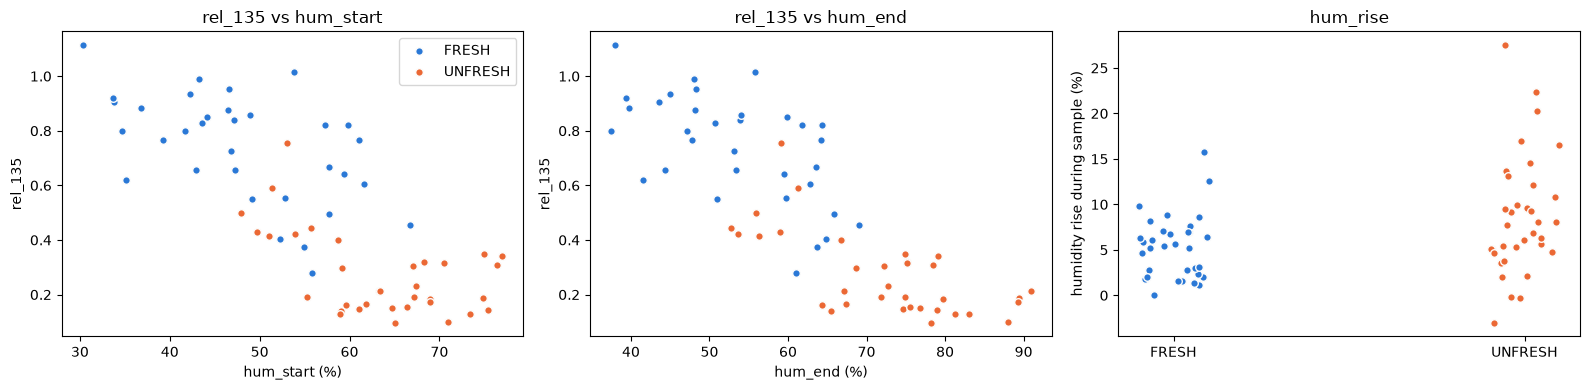

In [209]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for k, col in enumerate(["hum_start", "hum_end"]):
    for lab, color in [("FRESH", "#2a78d6"), ("UNFRESH", "#eb6834")]:
        g = feat[feat["label"] == lab]
        axes[k].scatter(g[col], g["rel_135"], color=color, s=30, edgecolor="#fcfcfb", label=lab)
    axes[k].set_xlabel(col + " (%)")
    axes[k].set_ylabel("rel_135")
    axes[k].set_title("rel_135 vs " + col)
axes[0].legend()

for j, (lab, color) in enumerate([("FRESH", "#2a78d6"), ("UNFRESH", "#eb6834")]):
    y = feat.loc[feat["label"] == lab, "hum_rise"].dropna()
    axes[2].scatter(j + np.random.uniform(-0.1, 0.1, len(y)), y, color=color, s=30, edgecolor="#fcfcfb")
axes[2].set_xticks([0, 1], ["FRESH", "UNFRESH"])
axes[2].set_ylabel("humidity rise during sample (%)")
axes[2].set_title("hum_rise")
plt.tight_layout()
plt.show()

## Humidity check: same humidity, still separated?

In [210]:
HUM_LO, HUM_HI = 50, 65    # only measurements whose box humidity at lid close is in this range

d = feat.dropna(subset=["hum_start", "rel_135"])
band = d[(d["hum_start"] >= HUM_LO) & (d["hum_start"] < HUM_HI)]
print(len(d), "with humidity,", len(band), f"in {HUM_LO}-{HUM_HI}%")
print(band.groupby("label")[["hum_start", "rel_137", "rel_135"]].agg(["count", "median"]).round(3), "\n")

# AUC = chance that a random FRESH has a higher rel than a random UNFRESH (0.5 = no separation, 1.0 = perfect)
for name, part in [("all", d), (f"{HUM_LO}-{HUM_HI}%", band)]:
    for col in ["rel_135", "rel_137"]:
        f = part.loc[part["label"] == "FRESH", col].dropna().values
        u = part.loc[part["label"] == "UNFRESH", col].dropna().values
        auc = (f[:, None] > u[None, :]).mean() + 0.5 * (f[:, None] == u[None, :]).mean()
        print(f"{name:8} {col}: AUC {auc:.3f}")
    # humidity alone, for comparison: chance that UNFRESH has the more humid box
    f = part.loc[part["label"] == "FRESH", "hum_start"].values
    u = part.loc[part["label"] == "UNFRESH", "hum_start"].values
    print(f"{name:8} hum_start alone: AUC {(u[:, None] > f[None, :]).mean() + 0.5 * (u[:, None] == f[None, :]).mean():.3f}\n")

67 with humidity, 28 in 50-65%
        hum_start        rel_137        rel_135       
            count median   count median   count median
label                                                 
FRESH          12   57.5      12  0.721      12  0.624
UNFRESH        16   59.0      15  0.578      16  0.214 

all      rel_135: AUC 0.958
all      rel_137: AUC 0.869
all      hum_start alone: AUC 0.888

50-65%   rel_135: AUC 0.870
50-65%   rel_137: AUC 0.733
50-65%   hum_start alone: AUC 0.583



26 pairs, FRESH has the higher rel_135 in 85% | median difference 0.278


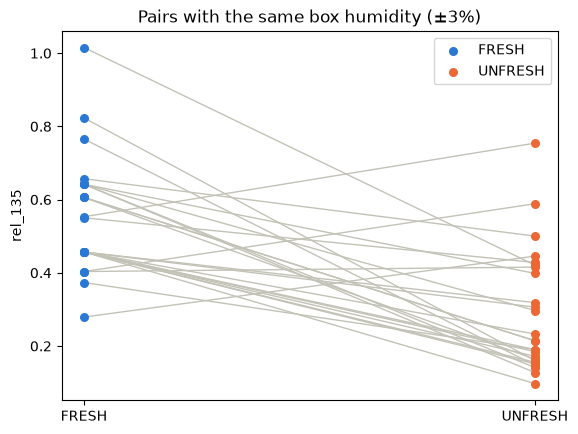

In [211]:
# matched pairs: each UNFRESH with the FRESH whose box humidity is closest (max 3% apart)
F = d[d["label"] == "FRESH"]
U = d[d["label"] == "UNFRESH"]
pairs = []
for _, u in U.iterrows():
    j = (F["hum_start"] - u["hum_start"]).abs().idxmin()
    if abs(F.loc[j, "hum_start"] - u["hum_start"]) <= 3:
        pairs.append({"unfresh": u["key"], "fresh": F.loc[j, "key"],
                      "hum_unfresh": u["hum_start"], "hum_fresh": F.loc[j, "hum_start"],
                      "rel135_unfresh": u["rel_135"], "rel135_fresh": F.loc[j, "rel_135"]})
pairs = pd.DataFrame(pairs)
higher = (pairs["rel135_fresh"] > pairs["rel135_unfresh"]).mean()
print(len(pairs), "pairs, FRESH has the higher rel_135 in", f"{higher:.0%}",
      "| median difference", round((pairs["rel135_fresh"] - pairs["rel135_unfresh"]).median(), 3))

for k in range(len(pairs)):
    plt.plot([0, 1], [pairs.loc[k, "rel135_fresh"], pairs.loc[k, "rel135_unfresh"]], color="#c3c2b7", linewidth=1)
plt.scatter(np.zeros(len(pairs)), pairs["rel135_fresh"], color="#2a78d6", s=30, zorder=3, label="FRESH")
plt.scatter(np.ones(len(pairs)), pairs["rel135_unfresh"], color="#eb6834", s=30, zorder=3, label="UNFRESH")
plt.xticks([0, 1], ["FRESH", "UNFRESH"])
plt.ylabel("rel_135")
plt.title("Pairs with the same box humidity (±3%)")
plt.legend()
plt.show()

## 1. Speed: how early after the lid closes can rel separate the labels?

In [212]:
TIMES = [30, 60, 90, 120, 180, 240, 300]   # seconds after the lid closes; rel = median of the 30 s before it

for s in ["137", "135"]:
    for T in TIMES:
        vals = []
        for i in range(len(df)):
            m = df.loc[i, "mq" + s + "_clean"]
            t = np.arange(len(m)) * df.loc[i, "intervalms"] / 1000
            w = m[(t >= T - 30) & (t < T)]
            w = w[~np.isnan(w)]
            rs_air = feat.loc[i, "rs_air_" + s]
            if len(w) < MIN_POINTS or np.isnan(rs_air) or t[-1] < T - 1:   # too few points, or sample shorter than T
                vals.append(np.nan)
                continue
            v = np.clip(w * df.loc[i, "vref"] / 1023, 0.01, None)
            vals.append(np.median(RL[s] * (VCC - v) / v) / rs_air)
        feat[f"rel{s}_t{T}"] = vals

# AUC per time: all measurements that reach T, and the same set for every T (samples >= 300 s)
same = feat[[f"rel{s}_t{T}" for s in ["137", "135"] for T in TIMES]].notna().all(axis=1)
rows = []
for T in TIMES:
    row = {"t_s": T}
    for s in ["137", "135"]:
        for name, part in [("all", feat), ("same", feat[same])]:
            col = f"rel{s}_t{T}"
            f = part.loc[part["label"] == "FRESH", col].dropna().values
            u = part.loc[part["label"] == "UNFRESH", col].dropna().values
            row[f"n_{s}_{name}"] = len(f) + len(u)
            row[f"auc_{s}_{name}"] = (f[:, None] > u[None, :]).mean() + 0.5 * (f[:, None] == u[None, :]).mean()
    rows.append(row)
speed = pd.DataFrame(rows)
speed.round(3)

,t_s,n_137_all,auc_137_all,n_137_same,auc_137_same,n_135_all,auc_135_all,n_135_same,auc_135_same
0,30,68,0.674,58,0.605,69,0.870,58,0.844
1,60,72,0.753,58,0.710,70,0.927,58,0.913
2,90,72,0.794,58,0.761,70,0.931,58,0.920
3,120,72,0.804,58,0.769,70,0.939,58,0.931
4,180,71,0.826,58,0.781,69,0.941,58,0.929
5,240,68,0.829,58,0.799,66,0.933,58,0.924
6,300,64,0.822,58,0.802,62,0.931,58,0.924


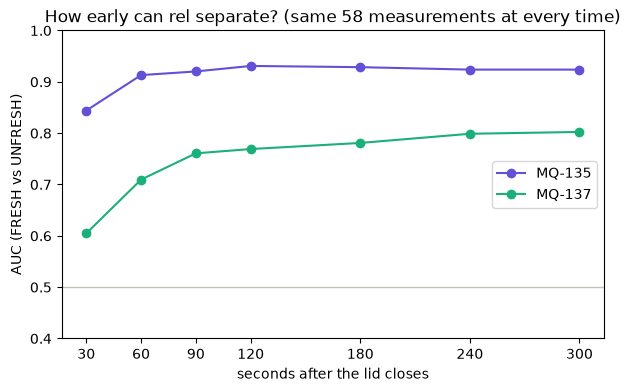

In [213]:
plt.figure(figsize=(7, 4))
plt.plot(speed["t_s"], speed["auc_135_same"], color="#6250d6", marker="o", label="MQ-135")
plt.plot(speed["t_s"], speed["auc_137_same"], color="#1baf7a", marker="o", label="MQ-137")
plt.axhline(0.5, color="#c3c2b7", linewidth=1)
plt.ylim(0.4, 1.0)
plt.xticks(TIMES)
plt.xlabel("seconds after the lid closes")
plt.ylabel("AUC (FRESH vs UNFRESH)")
plt.title(f"How early can rel separate? (same {int(same.sum())} measurements at every time)")
plt.legend()
plt.show()

## 2. Sensitivity: does the way rel is computed change the result?

In [214]:
is_fresh = (feat["label"] == "FRESH").values
rows = []
for win in [30, 60, 120]:                 # window at the end of each phase (s)
    for trim in [0, 10, 20]:              # seconds skipped at the end of the baseline
        for stat in ["median", "mean"]:
            row = {"window_s": win, "trim_s": trim, "stat": stat}
            for s in ["137", "135"]:
                rel = []
                for i in range(len(df)):
                    r = df.loc[i]
                    n_win = int(win * 1000 / r["intervalms"])
                    n_trim = int(trim * 1000 / r["intervalms"])
                    b = r["baseline" + s + "_clean"]
                    m = r["mq" + s + "_clean"]
                    b = b[~np.isnan(b)]
                    m = m[~np.isnan(m)]
                    b = b[: len(b) - n_trim][-n_win:]
                    m = m[-n_win:]
                    sat_end = (r["mq" + s][-n_win:] >= 1023).any()
                    if len(b) < MIN_POINTS or len(m) < MIN_POINTS or sat_end:
                        rel.append(np.nan)
                        continue
                    vb = np.clip(b * r["vref"] / 1023, 0.01, None)
                    vm = np.clip(m * r["vref"] / 1023, 0.01, None)
                    rs_b = RL[s] * (VCC - vb) / vb
                    rs_m = RL[s] * (VCC - vm) / vm
                    if stat == "median":
                        rel.append(np.median(rs_m) / np.median(rs_b))
                    else:
                        rel.append(rs_m.mean() / rs_b.mean())
                rel = np.array(rel)
                f = rel[is_fresh & ~np.isnan(rel)]
                u = rel[~is_fresh & ~np.isnan(rel)]
                row["auc_" + s] = (f[:, None] > u[None, :]).mean() + 0.5 * (f[:, None] == u[None, :]).mean()
            rows.append(row)

sens = pd.DataFrame(rows)
print("AUC range  MQ-137:", round(sens["auc_137"].min(), 3), "-", round(sens["auc_137"].max(), 3),
      "  MQ-135:", round(sens["auc_135"].min(), 3), "-", round(sens["auc_135"].max(), 3))
sens.round(3)

AUC range  MQ-137: 0.854 - 0.858   MQ-135: 0.947 - 0.952


,window_s,trim_s,stat,auc_137,auc_135
0,30,0,median,0.854,0.948
1,30,0,mean,0.855,0.948
2,30,10,median,0.856,0.948
3,30,10,mean,0.854,0.949
4,30,20,median,0.858,0.949
5,30,20,mean,0.857,0.949
6,60,0,median,0.858,0.952
7,60,0,mean,0.857,0.952
8,60,10,median,0.856,0.951
9,60,10,mean,0.856,0.951


## 3. Curve shape: slope, lowest point, average of the first 3 minutes

In [215]:
for s in ["137", "135"]:
    slope, low, mean180 = [], [], []
    for i in range(len(df)):
        r = df.loc[i]
        m = r["mq" + s + "_clean"]
        rs_air = feat.loc[i, "rs_air_" + s]
        t = np.arange(len(m)) * r["intervalms"] / 1000
        ok = ~np.isnan(m)
        if ok.sum() < MIN_POINTS or np.isnan(rs_air):
            slope.append(np.nan)
            low.append(np.nan)
            mean180.append(np.nan)
            continue
        v = np.clip(m * r["vref"] / 1023, 0.01, None)
        rel = RL[s] * (VCC - v) / v / rs_air                  # rel at every reading (NaN stays NaN)

        first = ok & (t < 120)
        slope.append(np.polyfit(t[first], rel[first], 1)[0] * 60 if first.sum() >= MIN_POINTS else np.nan)  # change per minute, first 2 min
        low.append(pd.Series(rel).rolling(5, center=True, min_periods=3).median().min())                   # lowest point, spikes smoothed out
        part = rel[ok & (t < 180)]
        mean180.append(part.mean() if len(part) >= MIN_POINTS else np.nan)                                 # average of the first 3 min
    feat["slope120_" + s] = slope
    feat["relmin_" + s] = low
    feat["mean180_" + s] = mean180

rows = []
for s in ["137", "135"]:
    for col in ["rel_" + s, f"rel{s}_t90", "slope120_" + s, "relmin_" + s, "mean180_" + s]:
        f = feat.loc[feat["label"] == "FRESH", col].dropna().values
        u = feat.loc[feat["label"] == "UNFRESH", col].dropna().values
        rows.append({"feature": col, "n": len(f) + len(u),
                     "median_FRESH": np.median(f), "median_UNFRESH": np.median(u),
                     "AUC": (f[:, None] > u[None, :]).mean() + 0.5 * (f[:, None] == u[None, :]).mean()})
pd.DataFrame(rows).round(3)

,feature,n,median_FRESH,median_UNFRESH,AUC
0,rel_137,72,0.771,0.546,0.856
1,rel137_t90,72,0.797,0.607,0.794
2,slope120_137,72,-0.024,-0.069,0.780
3,relmin_137,72,0.736,0.527,0.833
4,mean180_137,72,0.792,0.620,0.786
5,rel_135,70,0.766,0.214,0.951
6,rel135_t90,70,0.821,0.310,0.931
7,slope120_135,70,-0.032,-0.064,0.685
8,relmin_135,70,0.709,0.211,0.946
9,mean180_135,70,0.807,0.329,0.931


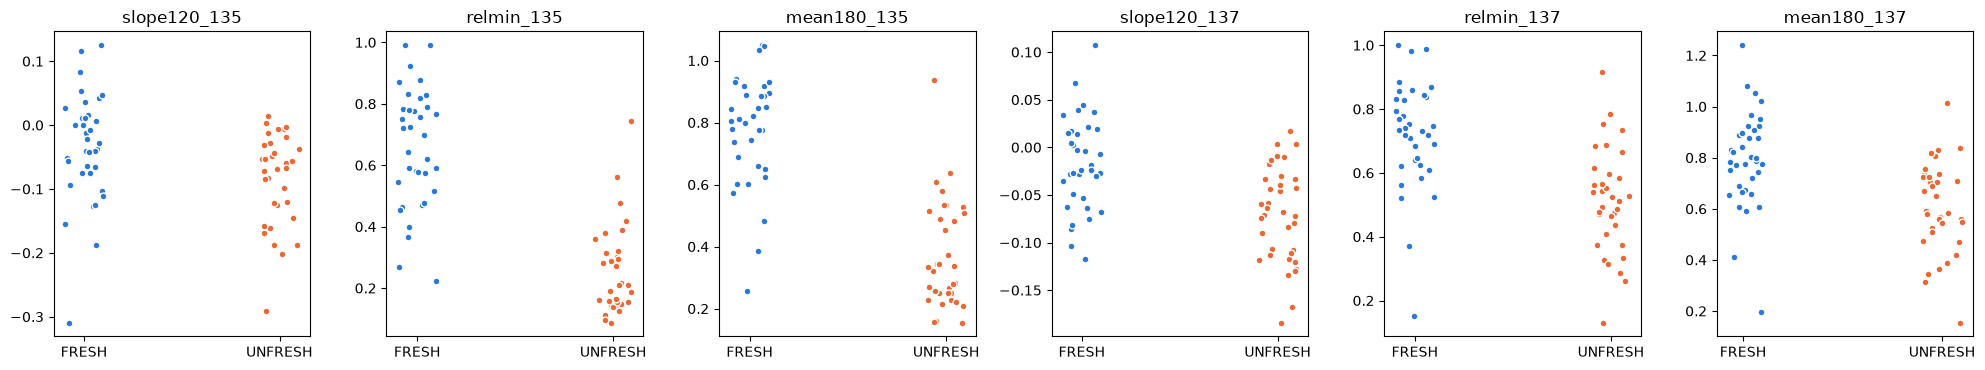

In [216]:
np.random.seed(0)
cols = ["slope120_135", "relmin_135", "mean180_135", "slope120_137", "relmin_137", "mean180_137"]
fig, axes = plt.subplots(1, 6, figsize=(20, 3.8))
for k, col in enumerate(cols):
    for j, (lab, color) in enumerate([("FRESH", "#2a78d6"), ("UNFRESH", "#eb6834")]):
        y = feat.loc[feat["label"] == lab, col].dropna()
        axes[k].scatter(j + np.random.uniform(-0.1, 0.1, len(y)), y, color=color, s=24, edgecolor="#fcfcfb")
    axes[k].set_xticks([0, 1], ["FRESH", "UNFRESH"])
    axes[k].set_title(col)
plt.tight_layout()
plt.show()

## 4. Correlation heatmap: which features move together?

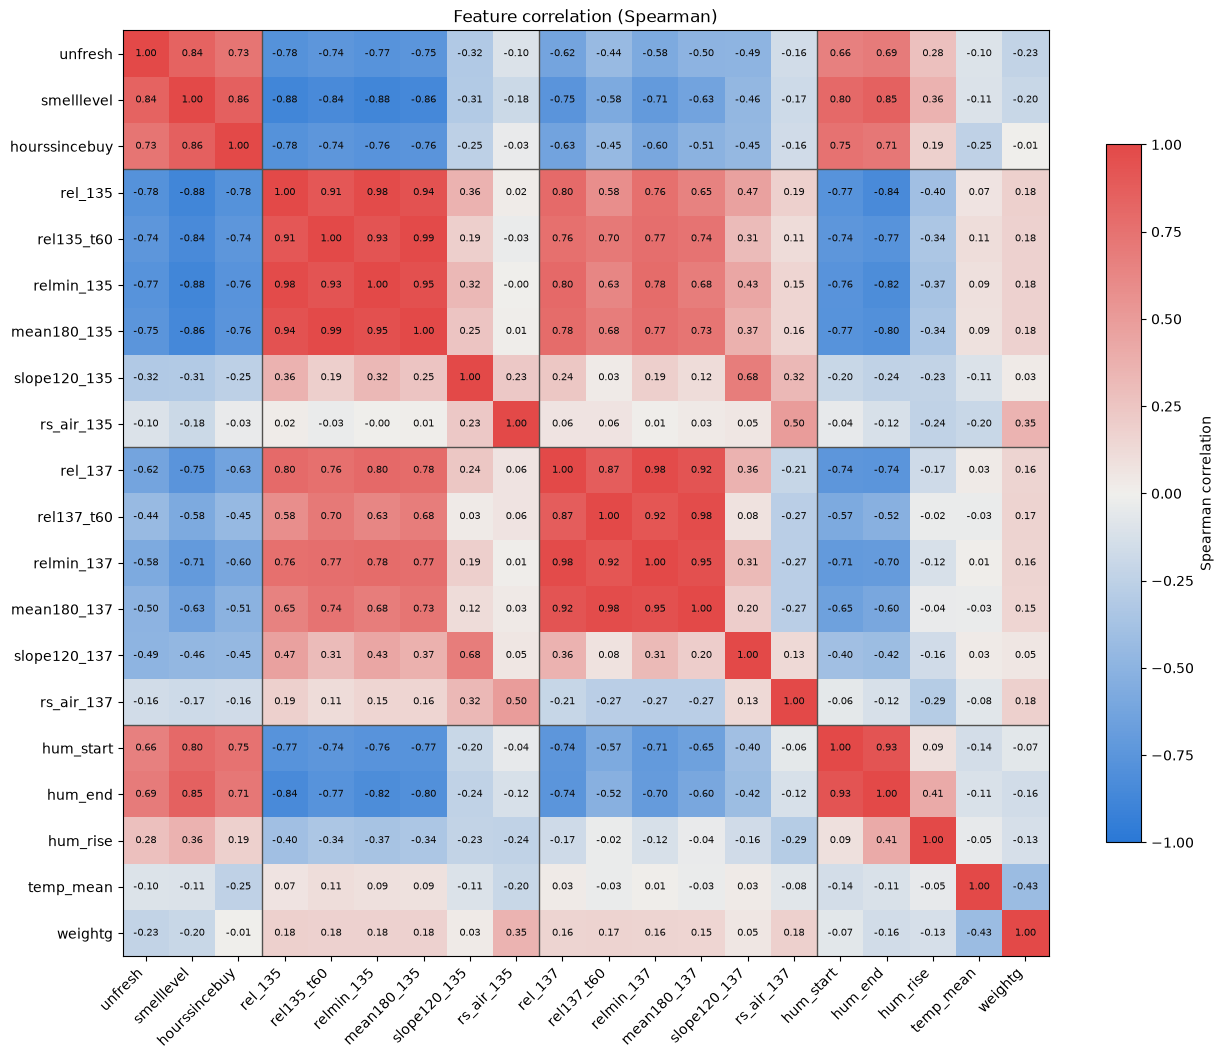

In [217]:
from matplotlib.colors import LinearSegmentedColormap

# Spearman = correlation of the ranks: works for smell level (1-5) and label (0/1) too, and one odd value cannot dominate
feat["unfresh"] = (feat["label"] == "UNFRESH").astype(int)
HEAT = ["unfresh", "smelllevel", "hourssincebuy",
        "rel_135", "rel135_t60", "relmin_135", "mean180_135", "slope120_135", "rs_air_135",
        "rel_137", "rel137_t60", "relmin_137", "mean180_137", "slope120_137", "rs_air_137",
        "hum_start", "hum_end", "hum_rise", "temp_mean", "weightg"]
corr = feat[HEAT].astype(float).corr(method="spearman")

cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])   # blue = negative, red = positive
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(HEAT)), HEAT, rotation=45, ha="right")
ax.set_yticks(range(len(HEAT)), HEAT)
for i in range(len(HEAT)):
    for j in range(len(HEAT)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color="#0b0b0b")
for k in [3, 9, 15]:                      # lines between the groups: target | MQ-135 | MQ-137 | environment
    ax.axhline(k - 0.5, color="#52514e", linewidth=1)
    ax.axvline(k - 0.5, color="#52514e", linewidth=1)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman correlation")
ax.set_title("Feature correlation (Spearman)")
plt.tight_layout()
plt.show()

In [218]:
# strongest pairs (each pair once, self-correlation left out)
pairs_corr = []
for i in range(len(HEAT)):
    for j in range(i + 1, len(HEAT)):
        pairs_corr.append({"a": HEAT[i], "b": HEAT[j], "r": corr.iloc[i, j]})
pairs_corr = pd.DataFrame(pairs_corr)
pairs_corr["abs_r"] = pairs_corr["r"].abs()
print("Top 15 pairs:")
print(pairs_corr.sort_values("abs_r", ascending=False).head(15)[["a", "b", "r"]].round(2).to_string(index=False), "\n")

# what goes with the label (unfresh = 1)
print("Correlation with unfresh (1 = UNFRESH):")
print(corr["unfresh"].drop("unfresh").sort_values(key=abs, ascending=False).round(2).to_string())

Top 15 pairs:
         a           b     r
rel135_t60 mean180_135  0.99
   rel_135  relmin_135  0.98
   rel_137  relmin_137  0.98
rel137_t60 mean180_137  0.98
relmin_137 mean180_137  0.95
relmin_135 mean180_135  0.95
   rel_135 mean180_135  0.94
 hum_start     hum_end  0.93
rel135_t60  relmin_135  0.93
   rel_137 mean180_137  0.92
rel137_t60  relmin_137  0.92
   rel_135  rel135_t60  0.91
smelllevel     rel_135 -0.88
smelllevel  relmin_135 -0.88
   rel_137  rel137_t60  0.87 

Correlation with unfresh (1 = UNFRESH):
smelllevel       0.84
rel_135         -0.78
relmin_135      -0.77
mean180_135     -0.75
rel135_t60      -0.74
hourssincebuy    0.73
hum_end          0.69
hum_start        0.66
rel_137         -0.62
relmin_137      -0.58
mean180_137     -0.50
slope120_137    -0.49
rel137_t60      -0.44
slope120_135    -0.32
hum_rise         0.28
weightg         -0.23
rs_air_137      -0.16
rs_air_135      -0.10
temp_mean       -0.10


rel_135_all vs rel_135: r = 0.97
rel_137_all vs rel_137: r = 0.97


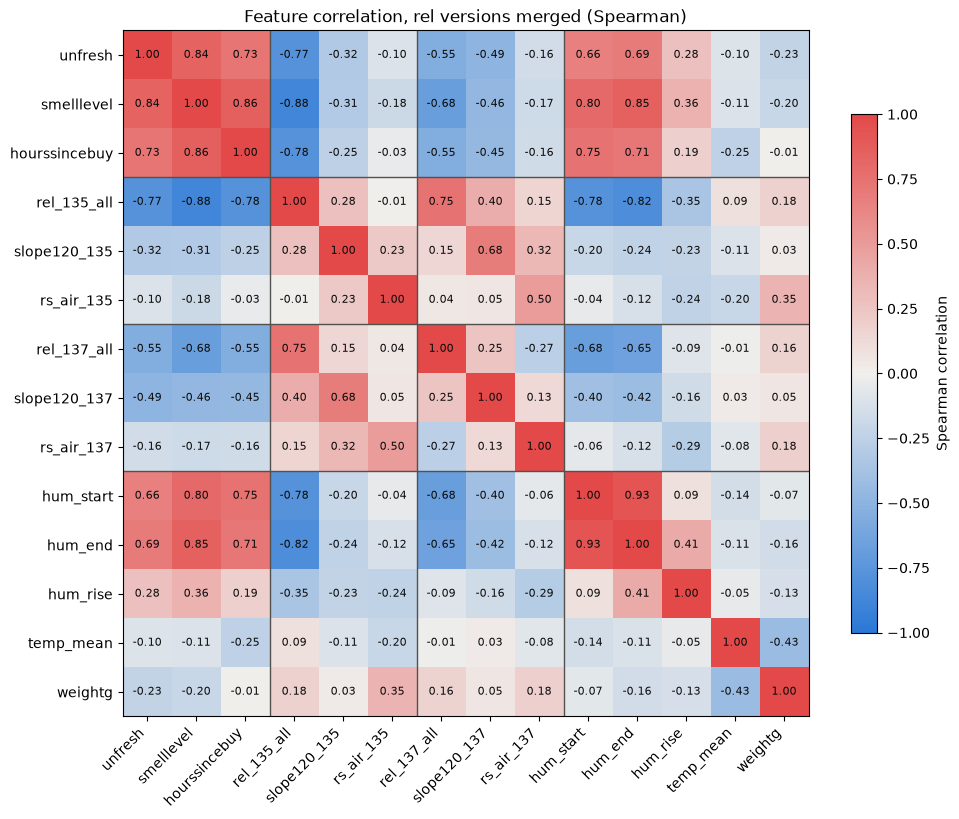

Correlation with unfresh (1 = UNFRESH):
smelllevel       0.84
rel_135_all     -0.77
hourssincebuy    0.73
hum_end          0.69
hum_start        0.66
rel_137_all     -0.55
slope120_137    -0.49
slope120_135    -0.32
hum_rise         0.28
weightg         -0.23
rs_air_137      -0.16
rs_air_135      -0.10
temp_mean       -0.10


In [219]:
# simpler view: the 4 rel versions per sensor are near-duplicates (r 0.87-0.99) -> average them into one column
for s in ["135", "137"]:
    parts = ["rel_" + s, f"rel{s}_t60", "relmin_" + s, "mean180_" + s]
    feat["rel_" + s + "_all"] = feat[parts].mean(axis=1, skipna=False)    # empty if any version is empty
    r = feat[["rel_" + s + "_all", "rel_" + s]].corr(method="spearman").iloc[0, 1]
    print(f"rel_{s}_all vs rel_{s}: r = {r:.2f}")

HEAT2 = ["unfresh", "smelllevel", "hourssincebuy",
         "rel_135_all", "slope120_135", "rs_air_135",
         "rel_137_all", "slope120_137", "rs_air_137",
         "hum_start", "hum_end", "hum_rise", "temp_mean", "weightg"]
corr2 = feat[HEAT2].astype(float).corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr2, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(HEAT2)), HEAT2, rotation=45, ha="right")
ax.set_yticks(range(len(HEAT2)), HEAT2)
for i in range(len(HEAT2)):
    for j in range(len(HEAT2)):
        ax.text(j, i, f"{corr2.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color="#0b0b0b")
for k in [3, 6, 9]:                       # target | MQ-135 | MQ-137 | environment
    ax.axhline(k - 0.5, color="#52514e", linewidth=1)
    ax.axvline(k - 0.5, color="#52514e", linewidth=1)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman correlation")
ax.set_title("Feature correlation, rel versions merged (Spearman)")
plt.tight_layout()
plt.show()

print("Correlation with unfresh (1 = UNFRESH):")
print(corr2["unfresh"].drop("unfresh").sort_values(key=abs, ascending=False).round(2).to_string())

## 5. First model: logistic regression + decision tree (split by chicken: train / validation / test)

In [220]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

# same rows for every model: rel_135, rel_137 and humidity all present (A01 has no humidity -> out)
mdata = feat.dropna(subset=["rel_135", "rel_137", "hum_start"]).reset_index(drop=True)
chickens = sorted(str(c) for c in mdata["chickenid"].unique())
print(len(mdata), "measurements,", len(chickens), "chickens")

# split by chicken: every chicken is in exactly one of train / validation / test -> no leakage
N_VAL, N_TEST = 3, 3
seed = 0
while True:
    order = [str(c) for c in np.random.default_rng(seed).permutation(chickens)]
    test_ch = sorted(order[:N_TEST])
    val_ch = sorted(order[N_TEST:N_TEST + N_VAL])
    train_ch = sorted(order[N_TEST + N_VAL:])
    ok = True
    for part in [val_ch, test_ch]:                       # validation and test both need FRESH and UNFRESH
        labels = mdata.loc[mdata["chickenid"].isin(part), "label"]
        if (labels == "FRESH").sum() < 3 or (labels == "UNFRESH").sum() < 3:
            ok = False
    if ok:
        break
    seed += 1

mdata["split"] = "train"
mdata.loc[mdata["chickenid"].isin(val_ch), "split"] = "val"
mdata.loc[mdata["chickenid"].isin(test_ch), "split"] = "test"
print("seed", seed)
print("train:", train_ch)
print("val:  ", val_ch)
print("test: ", test_ch, "\n")
print(pd.crosstab(mdata["split"], mdata["label"]))

66 measurements, 16 chickens
seed 0
train: ['A03', 'A07', 'A08', 'A09', 'A10', 'A11', 'A14', 'A15', 'A16', 'A17']
val:   ['A02', 'A06', 'A12']
test:  ['A04', 'A05', 'A13'] 

label  FRESH  UNFRESH
split                
test       8        7
train     15       22
val       10        4


In [221]:
# train on train, compare on validation. humidity = box humidity when the lid closes (hum_start)
FEATURE_SETS = {
    "rel_135": ["rel_135"],
    "rel_135 + rel_137": ["rel_135", "rel_137"],
    "humidity only": ["hum_start"],
    "rel_135 + rel_137 + humidity": ["rel_135", "rel_137", "hum_start"],
}
CANDIDATES = {}
for C in [0.1, 1, 10]:
    CANDIDATES["logistic C=" + str(C)] = make_pipeline(StandardScaler(), LogisticRegression(C=C))
for depth in [1, 2, 3]:
    CANDIDATES["tree depth=" + str(depth)] = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=3, random_state=0)

tr = mdata[mdata["split"] == "train"]
va = mdata[mdata["split"] == "val"]
rows = []
for fs_name, cols in FEATURE_SETS.items():
    for m_name, base in CANDIDATES.items():
        model = clone(base).fit(tr[cols].values, tr["unfresh"].values)
        p = model.predict_proba(va[cols].values)[:, 1]
        rows.append({"features": fs_name, "model": m_name,
                     "val_accuracy": accuracy_score(va["unfresh"], p >= 0.5),
                     "val_AUC": roc_auc_score(va["unfresh"], p)})
val_results = pd.DataFrame(rows)
val_results.round(3)

,features,model,val_accuracy,val_AUC
0,rel_135,logistic C=0.1,0.643,0.925
1,rel_135,logistic C=1,0.714,0.925
2,rel_135,logistic C=10,0.714,0.925
3,rel_135,tree depth=1,0.857,0.900
4,rel_135,tree depth=2,0.857,0.900
5,rel_135,tree depth=3,0.857,0.900
6,rel_135 + rel_137,logistic C=0.1,0.786,0.875
7,rel_135 + rel_137,logistic C=1,0.786,0.875
8,rel_135 + rel_137,logistic C=10,0.714,0.925
9,rel_135 + rel_137,tree depth=1,0.857,0.900


In [222]:
# per feature set: pick the best model on validation, retrain on train + validation, score the test chickens ONCE
trva = mdata[mdata["split"] != "test"]
te = mdata[mdata["split"] == "test"]
rows = []
final = {}
for fs_name, cols in FEATURE_SETS.items():
    best = val_results[val_results["features"] == fs_name].sort_values(["val_AUC", "val_accuracy"], ascending=False).iloc[0]
    model = clone(CANDIDATES[best["model"]]).fit(trva[cols].values, trva["unfresh"].values)
    p = model.predict_proba(te[cols].values)[:, 1]
    final[fs_name] = (model, p)
    rows.append({"features": fs_name, "chosen on val": best["model"], "val_AUC": best["val_AUC"],
                 "test_accuracy": accuracy_score(te["unfresh"], p >= 0.5),
                 "test_AUC": roc_auc_score(te["unfresh"], p)})
test_results = pd.DataFrame(rows)
print(len(te), "test measurements from", test_ch)
test_results.round(3)

15 test measurements from ['A04', 'A05', 'A13']


,features,chosen on val,val_AUC,test_accuracy,test_AUC
0,rel_135,logistic C=1,0.925,0.800,0.946
1,rel_135 + rel_137,logistic C=10,0.925,0.867,0.929
2,humidity only,tree depth=2,0.925,0.667,0.768
3,rel_135 + rel_137 + humidity,logistic C=1,0.975,0.733,0.929


In [223]:
from sklearn.metrics import precision_score, recall_score, f1_score, balanced_accuracy_score, classification_report

# positive class = UNFRESH (1): the one receiving must not let through
#   precision   = of everything flagged UNFRESH, how much really is UNFRESH
#   recall      = of all real UNFRESH, how much got caught            (a miss = spoiled chicken accepted)
#   specificity = of all real FRESH, how much was kept as FRESH       (a miss = good chicken rejected)
#   f1          = balance of precision and recall
#   AUC         = ranking quality of the probability, independent of the 0.5 threshold
y_true = te["unfresh"].values
rows = []
for fs_name, (model, p) in final.items():
    pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    rows.append({"features": fs_name,
                 "accuracy": accuracy_score(y_true, pred),
                 "balanced_acc": balanced_accuracy_score(y_true, pred),
                 "precision": precision_score(y_true, pred, zero_division=0),
                 "recall": recall_score(y_true, pred, zero_division=0),
                 "specificity": tn / (tn + fp),
                 "f1": f1_score(y_true, pred, zero_division=0),
                 "AUC": roc_auc_score(y_true, p),
                 "TP": tp, "FN": fn, "FP": fp, "TN": tn})
metrics = pd.DataFrame(rows)
print(len(y_true), "test measurements:", int(y_true.sum()), "UNFRESH,", int((1 - y_true).sum()), "FRESH\n")
print(classification_report(y_true, final["rel_135 + rel_137"][1] >= 0.5, labels=[0, 1],
                            target_names=["FRESH", "UNFRESH"], zero_division=0))
metrics.round(3)

15 test measurements: 7 UNFRESH, 8 FRESH

              precision    recall  f1-score   support

       FRESH       1.00      0.75      0.86         8
     UNFRESH       0.78      1.00      0.88         7

    accuracy                           0.87        15
   macro avg       0.89      0.88      0.87        15
weighted avg       0.90      0.87      0.87        15



,features,accuracy,balanced_acc,precision,recall,specificity,f1,AUC,TP,FN,FP,TN
0,rel_135,0.800,0.804,0.750,0.857,0.75,0.800,0.946,6,1,2,6
1,rel_135 + rel_137,0.867,0.875,0.778,1.000,0.75,0.875,0.929,7,0,2,6
2,humidity only,0.667,0.679,0.600,0.857,0.50,0.706,0.768,6,1,4,4
3,rel_135 + rel_137 + humidity,0.733,0.732,0.714,0.714,0.75,0.714,0.929,5,2,2,6


In [224]:
# look inside one model: the sensor-only model (no humidity)
fs_name = "rel_135 + rel_137"
cols = FEATURE_SETS[fs_name]
model, p = final[fs_name]

cm = confusion_matrix(te["unfresh"], p >= 0.5, labels=[0, 1])
print(pd.DataFrame(cm, index=["true FRESH", "true UNFRESH"], columns=["pred FRESH", "pred UNFRESH"]), "\n")

if isinstance(model, DecisionTreeClassifier):
    print(export_text(model, feature_names=cols))                       # the tree as if/else rules
else:
    coef = model[-1].coef_[0]
    print("logistic coefficients (per 1 std of each feature):", dict(zip(cols, coef.round(2))))
    print("negative = higher rel -> less likely UNFRESH\n")

out = te[["key", "label", "smelllevel", "rel_135", "rel_137", "hum_start"]].copy()
out["p_unfresh"] = p
out["pred"] = np.where(p >= 0.5, "UNFRESH", "FRESH")
out["correct"] = out["pred"] == out["label"]
out.round(3)

              pred FRESH  pred UNFRESH
true FRESH             6             2
true UNFRESH           0             7 

logistic coefficients (per 1 std of each feature): {'rel_135': np.float64(-4.2), 'rel_137': np.float64(1.1)}
negative = higher rel -> less likely UNFRESH



,key,label,smelllevel,rel_135,rel_137,hum_start,p_unfresh,pred,correct
9,A04_1h,FRESH,1,0.952,0.718,46.6,0.002,FRESH,True
10,A04_3h,FRESH,1,0.823,0.850,59.8,0.022,FRESH,True
11,A04_4h,FRESH,3,0.457,0.672,66.7,0.613,UNFRESH,False
12,A04_5h,UNFRESH,4,0.318,0.572,68.3,0.868,UNFRESH,True
13,A04_8h,UNFRESH,5,0.189,0.132,74.8,0.783,UNFRESH,True
14,A05_1h,FRESH,1,0.883,0.984,36.8,0.020,FRESH,True
15,A05_2h,FRESH,1,0.876,0.892,46.5,0.013,FRESH,True
16,A05_3h,FRESH,2,0.373,0.650,54.9,0.822,UNFRESH,False
17,A05_4h,FRESH,3,0.666,0.696,57.7,0.084,FRESH,True
18,A05_6h,UNFRESH,4,0.148,0.546,61.0,0.985,UNFRESH,True


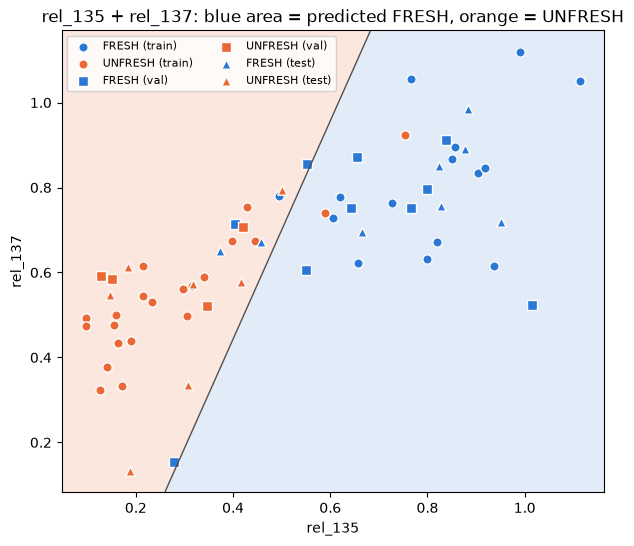

In [225]:
# decision boundary of the sensor-only model, all measurements shown (marker = split)
g135 = np.linspace(mdata["rel_135"].min() - 0.05, mdata["rel_135"].max() + 0.05, 200)
g137 = np.linspace(mdata["rel_137"].min() - 0.05, mdata["rel_137"].max() + 0.05, 200)
G135, G137 = np.meshgrid(g135, g137)
P = model.predict_proba(np.column_stack([G135.ravel(), G137.ravel()]))[:, 1].reshape(G135.shape)

plt.figure(figsize=(7, 6))
plt.contourf(G135, G137, P, levels=[0, 0.5, 1], colors=["#dbe8f8", "#fbe1d6"], alpha=0.8)
plt.contour(G135, G137, P, levels=[0.5], colors="#52514e", linewidths=1)
for split, marker in [("train", "o"), ("val", "s"), ("test", "^")]:
    for lab, color in [("FRESH", "#2a78d6"), ("UNFRESH", "#eb6834")]:
        g = mdata[(mdata["split"] == split) & (mdata["label"] == lab)]
        plt.scatter(g["rel_135"], g["rel_137"], color=color, marker=marker, s=45, edgecolor="#fcfcfb",
                    label=f"{lab} ({split})")
plt.xlabel("rel_135")
plt.ylabel("rel_137")
plt.title(f"{fs_name}: blue area = predicted FRESH, orange = UNFRESH")
plt.legend(fontsize=8, ncol=2)
plt.show()

## 6. Leave-one-chicken-out: threshold vs logistic vs tree, plus a high-recall threshold

In [226]:
RECALL_TARGET = 0.95     # for the "high recall" versions: catch at least 95% of UNFRESH on the training chickens

# no humidity needed here -> every measurement with rel_135 and rel_137 (A01 partly back in)
ldata = feat.dropna(subset=["rel_135", "rel_137"]).reset_index(drop=True)
ldata["chickenid"] = ldata["chickenid"].astype(str)
lchickens = sorted(ldata["chickenid"].unique())
X2 = ldata[["rel_135", "rel_137"]].values
y = ldata["unfresh"].values
print(len(ldata), "measurements,", len(lchickens), "chickens ->", len(lchickens), "rounds, each chicken is the test once")

METHODS = ["threshold rel_135 (balanced)", "threshold rel_135 (high recall)",
           "logistic (p >= 0.5)", "logistic (high recall)", "tree depth=2"]
score = {m: np.full(len(ldata), np.nan) for m in METHODS}   # higher = more likely UNFRESH (for AUC)
pred = {m: np.full(len(ldata), -1) for m in METHODS}         # 1 = UNFRESH
chosen = {m: [] for m in METHODS}                            # threshold picked in each round

for ch in lchickens:
    test = (ldata["chickenid"] == ch).values
    train = ~test
    ytr = y[train]

    # 1) threshold rule: UNFRESH if rel_135 < t. t is learned on the training chickens only
    r = ldata.loc[train, "rel_135"].values
    cands = np.unique(r)
    cands = (cands[:-1] + cands[1:]) / 2                  # midpoints between neighbouring values
    best_bal, t_bal, t_rec = -1, None, None
    for t in cands:                                       # small t -> strict, large t -> flags more
        flag = r < t
        rec = flag[ytr == 1].mean()
        spec = (~flag)[ytr == 0].mean()
        if (rec + spec) / 2 > best_bal:
            best_bal, t_bal = (rec + spec) / 2, t
        if t_rec is None and rec >= RECALL_TARGET:
            t_rec = t                                     # first t that reaches the target = keeps most FRESH
    if t_rec is None:
        t_rec = cands[-1]
    r_te = ldata.loc[test, "rel_135"].values
    for m, t in [("threshold rel_135 (balanced)", t_bal), ("threshold rel_135 (high recall)", t_rec)]:
        score[m][test] = -r_te
        pred[m][test] = (r_te < t).astype(int)
        chosen[m].append(t)

    # 2) logistic regression on rel_135 + rel_137, at p >= 0.5 and at a high-recall probability cut
    lr = make_pipeline(StandardScaler(), LogisticRegression(C=1)).fit(X2[train], ytr)
    p_tr = lr.predict_proba(X2[train])[:, 1]
    p_te = lr.predict_proba(X2[test])[:, 1]
    p_rec = None
    for pt in np.sort(np.unique(p_tr))[::-1]:             # from strict (high p) to loose
        if (p_tr[ytr == 1] >= pt).mean() >= RECALL_TARGET:
            p_rec = pt
            break
    for m, pt in [("logistic (p >= 0.5)", 0.5), ("logistic (high recall)", p_rec)]:
        score[m][test] = p_te
        pred[m][test] = (p_te >= pt).astype(int)
        chosen[m].append(pt)

    # 3) shallow tree on rel_135 + rel_137
    tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=3, random_state=0).fit(X2[train], ytr)
    score["tree depth=2"][test] = tree.predict_proba(X2[test])[:, 1]
    pred["tree depth=2"][test] = tree.predict(X2[test])

print("every measurement predicted:", all((pred[m] >= 0).all() for m in METHODS))

69 measurements, 17 chickens -> 17 rounds, each chicken is the test once
every measurement predicted: True


In [227]:
# metrics over all held-out predictions + a 95% range by resampling whole chickens (bootstrap)
rng = np.random.default_rng(0)
chicken_rows = [np.flatnonzero(ldata["chickenid"].values == c) for c in lchickens]
picks = [np.concatenate([chicken_rows[k] for k in rng.integers(0, len(lchickens), len(lchickens))]) for b in range(1000)]

rows = []
for m in METHODS:
    pr, sc = pred[m], score[m]
    tn, fp, fn, tp = confusion_matrix(y, pr, labels=[0, 1]).ravel()
    row = {"method": m,
           "recall": tp / (tp + fn), "specificity": tn / (tn + fp),
           "precision": tp / (tp + fp) if tp + fp else np.nan,
           "f1": f1_score(y, pr, zero_division=0), "balanced_acc": balanced_accuracy_score(y, pr),
           "AUC": roc_auc_score(y, sc), "missed UNFRESH (FN)": fn, "rejected FRESH (FP)": fp}
    boot = {"recall": [], "specificity": [], "f1": [], "AUC": []}
    for idx in picks:                                    # same resamples for every method -> fair comparison
        yb, pb, sb = y[idx], pr[idx], sc[idx]
        if yb.min() == yb.max():
            continue
        boot["recall"].append(pb[yb == 1].mean())
        boot["specificity"].append((1 - pb[yb == 0]).mean())
        boot["f1"].append(f1_score(yb, pb, zero_division=0))
        boot["AUC"].append(roc_auc_score(yb, sb))
    for k in boot:
        lo, hi = np.percentile(boot[k], [2.5, 97.5])
        row[k + " 95%"] = f"{lo:.2f}-{hi:.2f}"
    rows.append(row)

loco = pd.DataFrame(rows)
print(int(y.sum()), "UNFRESH,", int((1 - y).sum()), "FRESH, every prediction made by a model that never saw that chicken\n")
loco.round(3)

33 UNFRESH, 36 FRESH, every prediction made by a model that never saw that chicken



,method,recall,specificity,precision,f1,balanced_acc,AUC,missed UNFRESH (FN),rejected FRESH (FP),recall 95%,specificity 95%,f1 95%,AUC 95%
0,threshold rel_135 (balanced),0.879,0.833,0.829,0.853,0.856,0.949,4,6,0.78-0.97,0.73-0.93,0.77-0.92,0.90-0.99
1,threshold rel_135 (high recall),0.939,0.750,0.775,0.849,0.845,0.949,2,9,0.86-1.00,0.61-0.89,0.74-0.93,0.90-0.99
2,logistic (p >= 0.5),0.909,0.861,0.857,0.882,0.885,0.925,3,5,0.83-1.00,0.76-0.97,0.80-0.95,0.85-0.98
3,logistic (high recall),0.939,0.778,0.795,0.861,0.859,0.925,2,8,0.86-1.00,0.64-0.90,0.76-0.94,0.85-0.98
4,tree depth=2,0.879,0.833,0.829,0.853,0.856,0.882,4,6,0.78-0.97,0.73-0.93,0.77-0.92,0.80-0.96


In [228]:
# the threshold picked in each round -> how stable is it, and what rule would go on the device
for m in METHODS[:4]:
    v = np.array(chosen[m], dtype=float)
    unit = "rel_135 <" if m.startswith("threshold") else "p_unfresh >="
    print(f"{m:33} {unit} {np.median(v):.3f}   (range {v.min():.3f}-{v.max():.3f} over {len(v)} rounds)")

# which measurements the simplest rule gets wrong
m = "threshold rel_135 (balanced)"
wrong = ldata.loc[pred[m] != y, ["key", "label", "smelllevel", "hourssincebuy", "rel_135", "rel_137"]]
print(f"\n{m}: {len(wrong)} wrong of {len(ldata)}")
wrong.round(3)

threshold rel_135 (balanced)      rel_135 < 0.451   (range 0.442-0.525 over 17 rounds)
threshold rel_135 (high recall)   rel_135 < 0.589   (range 0.525-0.597 over 17 rounds)
logistic (p >= 0.5)               p_unfresh >= 0.500   (range 0.500-0.500 over 17 rounds)
logistic (high recall)            p_unfresh >= 0.287   (range 0.259-0.417 over 17 rounds)

threshold rel_135 (balanced): 10 wrong of 69


,key,label,smelllevel,hourssincebuy,rel_135,rel_137
2,A01_4h,FRESH,3,4,0.315,0.470
5,A02_3h,FRESH,2,3,0.279,0.155
6,A02_4h,FRESH,3,4,0.403,0.713
9,A03_4h,FRESH,2,4,0.495,0.779
14,A04_4h,FRESH,3,4,0.457,0.672
19,A05_3h,FRESH,2,3,0.373,0.650
36,A08_3h,UNFRESH,3,3,0.589,0.741
44,A10_3h,UNFRESH,2,3,0.754,0.923
50,A11_7h,UNFRESH,4,7,0.446,0.675
56,A13_4h,UNFRESH,3,4,0.500,0.795


In [229]:
# does class_weight help? same leave-one-chicken-out, default cut (p >= 0.5 / tree.predict)
#   None       = every measurement counts the same
#   balanced   = classes weighted by 1 / their size (33 vs 36 -> almost no change)
#   UNFRESH x2 = a missed UNFRESH costs twice as much as a rejected FRESH (pushes towards recall)
WEIGHTS = {"None": None, "balanced": "balanced", "UNFRESH x2": {0: 1, 1: 2}, "UNFRESH x3": {0: 1, 1: 3}}

rows = []
for model_name in ["logistic", "tree depth=2"]:
    for w_name, w in WEIGHTS.items():
        sc = np.full(len(ldata), np.nan)
        pr = np.full(len(ldata), -1)
        for ch in lchickens:
            test = (ldata["chickenid"] == ch).values
            train = ~test
            if model_name == "logistic":
                mdl = make_pipeline(StandardScaler(), LogisticRegression(C=1, class_weight=w))
            else:
                mdl = DecisionTreeClassifier(max_depth=2, min_samples_leaf=3, class_weight=w, random_state=0)
            mdl.fit(X2[train], y[train])
            sc[test] = mdl.predict_proba(X2[test])[:, 1]
            pr[test] = mdl.predict(X2[test])
        tn, fp, fn, tp = confusion_matrix(y, pr, labels=[0, 1]).ravel()
        rows.append({"model": model_name, "class_weight": w_name,
                     "recall": tp / (tp + fn), "specificity": tn / (tn + fp),
                     "f1": f1_score(y, pr, zero_division=0), "AUC": roc_auc_score(y, sc),
                     "missed UNFRESH (FN)": fn, "rejected FRESH (FP)": fp})
pd.DataFrame(rows).round(3)

,model,class_weight,recall,specificity,f1,AUC,missed UNFRESH (FN),rejected FRESH (FP)
0,logistic,None,0.909,0.861,0.882,0.925,3,5
1,logistic,balanced,0.909,0.833,0.870,0.928,3,6
2,logistic,UNFRESH x2,0.939,0.778,0.861,0.929,2,8
3,logistic,UNFRESH x3,0.939,0.750,0.849,0.934,2,9
4,tree depth=2,None,0.879,0.833,0.853,0.882,4,6
5,tree depth=2,balanced,0.879,0.833,0.853,0.884,4,6
6,tree depth=2,UNFRESH x2,0.879,0.778,0.829,0.884,4,8
7,tree depth=2,UNFRESH x3,0.909,0.750,0.833,0.828,3,9


## 7. Three classes: FRESH (segar) / CHECK (perlu dicek) / SPOILED (busuk), from smell level

In [230]:
# target from smell level, ordered: 0 = FRESH (smell 1-2), 1 = CHECK (smell 3), 2 = SPOILED (smell 4-5)
CLASSES = ["FRESH", "CHECK", "SPOILED"]
ldata["cls"] = np.select([ldata["smelllevel"] <= 2, ldata["smelllevel"] == 3], [0, 1], default=2)
yc = ldata["cls"].values
print(pd.crosstab([ldata["cls"].map(dict(enumerate(CLASSES))), ldata["smelllevel"]], ldata["label"]), "\n")

pred3 = {"two thresholds rel_135": np.full(len(ldata), -1), "multinomial logistic": np.full(len(ldata), -1)}
cuts = []
for ch in lchickens:
    test = (ldata["chickenid"] == ch).values
    train = ~test
    ytr = yc[train]

    # 1) two thresholds on rel_135, learned on the training chickens: pick (t1, t2) with the best balanced accuracy
    r = ldata.loc[train, "rel_135"].values
    cands = np.unique(r)
    cands = (cands[:-1] + cands[1:]) / 2
    best, best_pair = -1, None
    for a in range(len(cands)):
        for b in range(a + 1, len(cands)):
            p = np.where(r < cands[a], 2, np.where(r < cands[b], 1, 0))
            bal = np.mean([(p[ytr == k] == k).mean() for k in range(3)])   # average recall of the 3 classes
            if bal > best:
                best, best_pair = bal, (cands[a], cands[b])
    t1, t2 = best_pair
    cuts.append(best_pair)
    r_te = ldata.loc[test, "rel_135"].values
    pred3["two thresholds rel_135"][test] = np.where(r_te < t1, 2, np.where(r_te < t2, 1, 0))

    # 2) multinomial logistic regression on rel_135 + rel_137
    lr3 = make_pipeline(StandardScaler(), LogisticRegression(C=1)).fit(X2[train], ytr)
    pred3["multinomial logistic"][test] = lr3.predict(X2[test])

cuts = np.array(cuts)
print(f"SPOILED if rel_135 < {np.median(cuts[:, 0]):.3f} (range {cuts[:, 0].min():.3f}-{cuts[:, 0].max():.3f}),",
      f"CHECK if below {np.median(cuts[:, 1]):.3f} (range {cuts[:, 1].min():.3f}-{cuts[:, 1].max():.3f}), else FRESH")

label               FRESH  UNFRESH
cls     smelllevel                
CHECK   3               6        7
FRESH   1              19        0
        2              11        1
SPOILED 4               0       13
        5               0       12 

SPOILED if rel_135 < 0.401 (range 0.256-0.401), CHECK if below 0.589 (range 0.476-0.597), else FRESH


In [231]:
# how good, and how dangerous are the mistakes?
#   dangerous = really SPOILED but predicted FRESH (accepted at receiving)
#   wasted    = really FRESH but predicted SPOILED (rejected without a re-check)
#   off by one class (e.g. CHECK vs SPOILED) is a mild mistake: CHECK means "re-check", not "accept"
rows = []
for m, pr in pred3.items():
    cm = confusion_matrix(yc, pr, labels=[0, 1, 2])
    print(m)
    print(pd.DataFrame(cm, index=["true " + c for c in CLASSES], columns=["pred " + c for c in CLASSES]), "\n")
    row = {"method": m,
           "accuracy": (pr == yc).mean(),
           "balanced_acc": np.mean([(pr[yc == k] == k).mean() for k in range(3)]),
           "macro_f1": f1_score(yc, pr, average="macro", zero_division=0),
           "within 1 class": (np.abs(pr - yc) <= 1).mean(),
           "dangerous (SPOILED->FRESH)": int(cm[2, 0]),
           "wasted (FRESH->SPOILED)": int(cm[0, 2])}
    for k, c in enumerate(CLASSES):
        row["recall " + c] = (pr[yc == k] == k).mean()
    # compared with the original binary label: UNFRESH chickens that would be accepted (predicted FRESH)
    row["UNFRESH label accepted"] = int(((ldata["label"] == "UNFRESH").values & (pr == 0)).sum())
    rows.append(row)
pd.DataFrame(rows).round(3)

two thresholds rel_135
              pred FRESH  pred CHECK  pred SPOILED
true FRESH            25           5             1
true CHECK             5           5             3
true SPOILED           0           7            18 

multinomial logistic
              pred FRESH  pred CHECK  pred SPOILED
true FRESH            28           1             2
true CHECK             7           2             4
true SPOILED           0           2            23 



,method,accuracy,balanced_acc,macro_f1,within 1 class,dangerous (SPOILED->FRESH),wasted (FRESH->SPOILED),recall FRESH,recall CHECK,recall SPOILED,UNFRESH label accepted
0,two thresholds rel_135,0.696,0.637,0.640,0.986,0,1,0.806,0.385,0.72,3
1,multinomial logistic,0.768,0.659,0.641,0.971,0,2,0.903,0.154,0.92,4


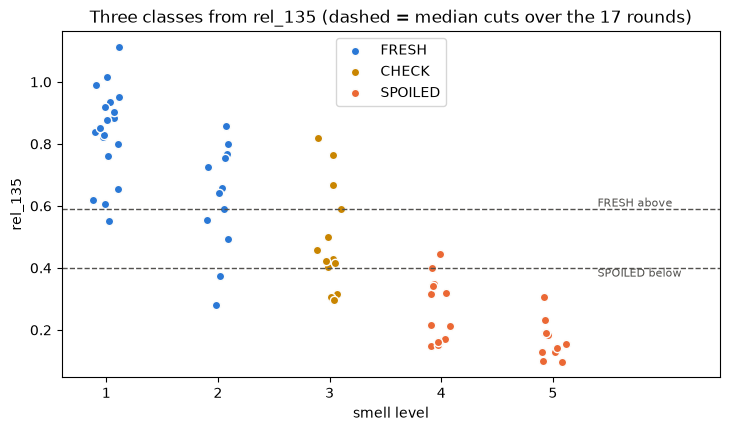

In [232]:
# picture: rel_135 per smell level, coloured by the 3-class target, with the median cut lines
np.random.seed(0)
colors = ["#2a78d6", "#c98500", "#eb6834"]
plt.figure(figsize=(8.5, 4.5))
for k, c in enumerate(CLASSES):
    g = ldata[ldata["cls"] == k]
    plt.scatter(g["smelllevel"] + np.random.uniform(-0.12, 0.12, len(g)), g["rel_135"],
                color=colors[k], s=36, edgecolor="#fcfcfb", label=c)
plt.axhline(np.median(cuts[:, 0]), color="#52514e", linewidth=1, linestyle="--")
plt.axhline(np.median(cuts[:, 1]), color="#52514e", linewidth=1, linestyle="--")
plt.text(5.4, np.median(cuts[:, 0]), "SPOILED below", va="top", fontsize=8, color="#52514e")
plt.text(5.4, np.median(cuts[:, 1]), "FRESH above", va="bottom", fontsize=8, color="#52514e")
plt.xticks([1, 2, 3, 4, 5])
plt.xlim(0.6, 6.5)
plt.xlabel("smell level")
plt.ylabel("rel_135")
plt.title("Three classes from rel_135 (dashed = median cuts over the 17 rounds)")
plt.legend(loc="upper center")
plt.show()

## 8. Segar vs tidak segar: sweet spot between recall and specificity

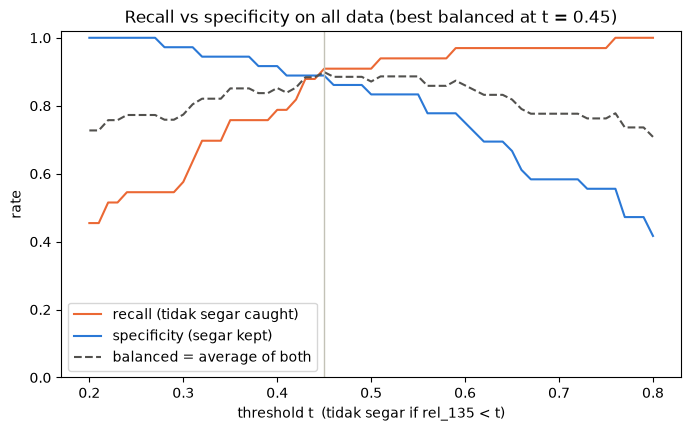

   t  recall  specificity  balanced
0.38   0.758        0.917     0.837
0.39   0.758        0.917     0.837
0.40   0.788        0.917     0.852
0.41   0.788        0.889     0.838
0.42   0.818        0.889     0.854
0.43   0.879        0.889     0.884
0.44   0.879        0.889     0.884
0.45   0.909        0.889     0.899
0.46   0.909        0.861     0.885
0.47   0.909        0.861     0.885
0.48   0.909        0.861     0.885
0.49   0.909        0.861     0.885
0.50   0.909        0.833     0.871
0.51   0.939        0.833     0.886
0.52   0.939        0.833     0.886
0.53   0.939        0.833     0.886
0.54   0.939        0.833     0.886
0.55   0.939        0.833     0.886
0.56   0.939        0.778     0.859
0.57   0.939        0.778     0.859
0.58   0.939        0.778     0.859
0.59   0.970        0.778     0.874
0.60   0.970        0.750     0.860
0.61   0.970        0.722     0.846
0.62   0.970        0.694     0.832


In [233]:
# trade-off curve: every cut on rel_135 ("tidak segar" if rel_135 < t), on all measurements
# descriptive only: the honest numbers are in the next cell, where t is picked without seeing the test chicken
ts = np.round(np.arange(0.20, 0.80, 0.01), 2)
curve = []
for t in ts:
    flag = ldata["rel_135"].values < t
    curve.append({"t": t, "recall": flag[y == 1].mean(), "specificity": (~flag)[y == 0].mean()})
curve = pd.DataFrame(curve)
curve["balanced"] = (curve["recall"] + curve["specificity"]) / 2
best_t = curve.loc[curve["balanced"].idxmax(), "t"]

plt.figure(figsize=(8, 4.5))
plt.plot(curve["t"], curve["recall"], color="#eb6834", label="recall (tidak segar caught)")
plt.plot(curve["t"], curve["specificity"], color="#2a78d6", label="specificity (segar kept)")
plt.plot(curve["t"], curve["balanced"], color="#52514e", linestyle="--", label="balanced = average of both")
plt.axvline(best_t, color="#c3c2b7", linewidth=1)
plt.xlabel("threshold t  (tidak segar if rel_135 < t)")
plt.ylabel("rate")
plt.ylim(0, 1.02)
plt.title(f"Recall vs specificity on all data (best balanced at t = {best_t:.2f})")
plt.legend()
plt.show()

print(curve[(curve["t"] >= 0.38) & (curve["t"] <= 0.62)].round(3).to_string(index=False))

In [234]:
# honest version: in every leave-one-chicken-out round, pick t on the training chickens only.
# three definitions of "balanced":
#   youden = highest recall + specificity (= balanced accuracy)  -> the standard sweet spot
#   equal  = recall and specificity as close to each other as possible
#   f1     = highest F1 for "tidak segar"
CRITERIA = ["youden", "equal", "f1"]
pred_b = {c: np.full(len(ldata), -1) for c in CRITERIA}
t_b = {c: [] for c in CRITERIA}
for ch in lchickens:
    test = (ldata["chickenid"] == ch).values
    train = ~test
    r = ldata.loc[train, "rel_135"].values
    ytr = y[train]
    cands = np.unique(r)
    cands = (cands[:-1] + cands[1:]) / 2
    best = {"youden": (-1, None), "equal": (9, None), "f1": (-1, None)}
    for t in cands:
        flag = r < t
        rec = flag[ytr == 1].mean()
        spec = (~flag)[ytr == 0].mean()
        prec = flag[ytr == 1].sum() / max(flag.sum(), 1)
        f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0
        if rec + spec > best["youden"][0]:
            best["youden"] = (rec + spec, t)
        if abs(rec - spec) < best["equal"][0]:
            best["equal"] = (abs(rec - spec), t)
        if f1 > best["f1"][0]:
            best["f1"] = (f1, t)
    r_te = ldata.loc[test, "rel_135"].values
    for c in CRITERIA:
        t_b[c].append(best[c][1])
        pred_b[c][test] = (r_te < best[c][1]).astype(int)

rows = []
for c in CRITERIA:
    pr = pred_b[c]
    tn, fp, fn, tp = confusion_matrix(y, pr, labels=[0, 1]).ravel()
    row = {"criterion": c, "threshold (median)": np.median(t_b[c]),
           "recall": tp / (tp + fn), "specificity": tn / (tn + fp), "precision": tp / (tp + fp),
           "f1": f1_score(y, pr), "balanced_acc": balanced_accuracy_score(y, pr),
           "missed tidak segar": fn, "segar flagged": fp,
           "smell-1 segar flagged": int(((y == 0) & (pr == 1) & (ldata["smelllevel"].values == 1)).sum())}
    rec_b, spec_b = [], []
    for idx in picks:                                   # same chicken resamples as section 6
        yb, pb = y[idx], pr[idx]
        if yb.min() == yb.max():
            continue
        rec_b.append(pb[yb == 1].mean())
        spec_b.append((1 - pb[yb == 0]).mean())
    row["recall 95%"] = f"{np.percentile(rec_b, 2.5):.2f}-{np.percentile(rec_b, 97.5):.2f}"
    row["specificity 95%"] = f"{np.percentile(spec_b, 2.5):.2f}-{np.percentile(spec_b, 97.5):.2f}"
    rows.append(row)
pd.DataFrame(rows).round(3)

,criterion,threshold (median),recall,specificity,precision,f1,balanced_acc,missed tidak segar,segar flagged,smell-1 segar flagged,recall 95%,specificity 95%
0,youden,0.451,0.879,0.833,0.829,0.853,0.856,4,6,0,0.78-0.97,0.73-0.93
1,equal,0.437,0.879,0.889,0.879,0.879,0.884,4,4,0,0.78-0.97,0.79-1.00
2,f1,0.451,0.879,0.833,0.829,0.853,0.856,4,6,0,0.78-0.97,0.73-0.93


In [235]:
# who does the sweet-spot rule get wrong?
pr = pred_b["youden"]
print("tidak segar, but said segar:")
print(ldata.loc[(y == 1) & (pr == 0), ["key", "smelllevel", "hourssincebuy", "rel_135"]].round(3).to_string(index=False))
print("\nsegar, but said tidak segar:")
print(ldata.loc[(y == 0) & (pr == 1), ["key", "smelllevel", "hourssincebuy", "rel_135"]].round(3).to_string(index=False))

tidak segar, but said segar:
   key  smelllevel  hourssincebuy  rel_135
A08_3h           3              3    0.589
A10_3h           2              3    0.754
A11_7h           4              7    0.446
A13_4h           3              4    0.500

segar, but said tidak segar:
   key  smelllevel  hourssincebuy  rel_135
A01_4h           3              4    0.315
A02_3h           2              3    0.279
A02_4h           3              4    0.403
A03_4h           2              4    0.495
A04_4h           3              4    0.457
A05_3h           2              3    0.373


## 9. Export the model (input: rel_135, rel_137)

In [236]:
import json, os, joblib
from datetime import date

# final model: logistic regression on rel_135 + rel_137, trained on ALL measurements
# its expected performance on new chickens = the leave-one-chicken-out numbers from section 6
final_model = make_pipeline(StandardScaler(), LogisticRegression(C=1)).fit(X2, y)
scaler, lr_final = final_model[0], final_model[1]
THRESHOLD = 0.5            # p_tidak_segar >= THRESHOLD -> "tidak segar"  (keep it in the app config)

loco_row = loco[loco["method"] == "logistic (p >= 0.5)"].iloc[0]
export = {
    "name": "chicken-freshness-logreg",
    "version": "1.0",
    "created": str(date.today()),
    "output": {"0": "segar", "1": "tidak segar"},
    "features": ["rel_135", "rel_137"],
    "scaler_mean": scaler.mean_.tolist(),
    "scaler_scale": scaler.scale_.tolist(),
    "coef": lr_final.coef_[0].tolist(),
    "intercept": float(lr_final.intercept_[0]),
    "threshold": THRESHOLD,
    "how_to_predict": "z = (x - scaler_mean) / scaler_scale; p = 1 / (1 + exp(-(intercept + sum(coef * z)))); tidak segar if p >= threshold",
    "rel_computation": {
        "rl_kohm": RL,
        "vcc": VCC,
        "volt": "V = raw * vref / 1023   (vref of the device, 5.0 V)",
        "rs": "Rs = RL * (VCC - V) / V   (V clipped at >= 0.01)",
        "rs_air": f"median Rs of the baseline (empty box, lid closed): skip its last {TRIM_END_S} s, then take the {WINDOW_S} s before",
        "rs_sample": f"median Rs of the last {WINDOW_S} s of the sample (chicken in, lid closed)",
        "rel": "rel = rs_sample / rs_air, per sensor",
        "min_points": MIN_POINTS,
        "invalid_if": "fewer than min_points readings in a window, or any raw >= 1023 in the sample window",
    },
    "trained_on": {"measurements": int(len(ldata)), "chickens": len(lchickens),
                   "tidak_segar": int(y.sum()), "segar": int((1 - y).sum())},
    "expected_performance_leave_one_chicken_out": {k: round(float(loco_row[k]), 3)
                                                   for k in ["recall", "specificity", "precision", "f1", "AUC"]},
}
os.makedirs("../models", exist_ok=True)
with open("../models/freshness_model.json", "w") as fh:
    json.dump(export, fh, indent=2)
joblib.dump(final_model, "../models/freshness_model.joblib")
print(json.dumps(export, indent=2))

{
  "name": "chicken-freshness-logreg",
  "version": "1.0",
  "created": "2026-10-27",
  "output": {
    "0": "segar",
    "1": "tidak segar"
  },
  "features": [
    "rel_135",
    "rel_137"
  ],
  "scaler_mean": [
    0.5098714884469172,
    0.6581832595748461
  ],
  "scaler_scale": [
    0.2870141870963004,
    0.19896999855528152
  ],
  "coef": [
    -2.34607662135736,
    0.051083979317173414
  ],
  "intercept": -0.30252942199843247,
  "threshold": 0.5,
  "how_to_predict": "z = (x - scaler_mean) / scaler_scale; p = 1 / (1 + exp(-(intercept + sum(coef * z)))); tidak segar if p >= threshold",
  "rel_computation": {
    "rl_kohm": {
      "137": 1.0,
      "135": 2.0
    },
    "vcc": 5.0,
    "volt": "V = raw * vref / 1023   (vref of the device, 5.0 V)",
    "rs": "Rs = RL * (VCC - V) / V   (V clipped at >= 0.01)",
    "rs_air": "median Rs of the baseline (empty box, lid closed): skip its last 10 s, then take the 60 s before",
    "rs_sample": "median Rs of the last 60 s of the samp

In [ ]:
# check: the plain formula in the JSON gives the same probability as sklearn -> this is what the app implements
with open("../models/freshness_model.json") as fh:
    m = json.load(fh)
p_json = 1 / (1 + np.exp(-(m["intercept"] + z @ np.array(m["coef"]))))
print("max difference JSON formula vs sklearn:", np.abs(p_json - final_model.predict_proba(X2)[:, 1]).max())

# example: one measurement from RAW readings to a result, the same steps the app does
key = "A05_6h"
i = df.index[df["key"] == key][0]
r = df.loc[i]
n_win = int(WINDOW_S * 1000 / r["intervalms"])
n_trim = int(TRIM_END_S * 1000 / r["intervalms"])
x = []
for s in ["135", "137"]:
    b = r["baseline" + s][: len(r["baseline" + s]) - n_trim][-n_win:]     # raw baseline window
    mm = r["mq" + s][-n_win:]                                             # raw sample window
    vb = np.clip(b * r["vref"] / 1023, 0.01, None)
    vm = np.clip(mm * r["vref"] / 1023, 0.01, None)
    rel = np.median(RL[s] * (VCC - vm) / vm) / np.median(RL[s] * (VCC - vb) / vb)
    x.append(rel)
z = (np.array(x) - np.array(m["scaler_mean"])) / np.array(m["scaler_scale"])
p = 1 / (1 + np.exp(-(m["intercept"] + z @ np.array(m["coef"]))))
result = m["output"]["1"] if p >= m["threshold"] else m["output"]["0"]
print(f"{key}: rel_135 = {x[0]:.3f}, rel_137 = {x[1]:.3f} -> p(tidak segar) = {p:.3f} -> {result}  (true label: {r['label']})")

max difference JSON formula vs sklearn: 0.0
A05_6h: rel_135 = 0.148, rel_137 = 0.546 -> p(tidak segar) = 0.933 -> tidak segar  (true label: UNFRESH)
